# Task 19 — Hotel cancellations and overbooking: how many rooms to oversell tonight

**Study unit:** ARI3217 — AI Enterprise Architectures and Transformation (University of Malta)
**Dataset:** [Hotel booking demand](https://www.kaggle.com/datasets/jessemostipak/hotel-booking-demand) (a city hotel and a resort hotel in Portugal, arrivals Jul 2015 – Aug 2017; Antonio, Almeida and Nunes, *Data in Brief*, 2019)
**Task family:** tabular supervised learning, calibration, a cost-based decision, temporal validation and drift · **Companion task:** `02_card_fraud_tabular.ipynb` (the same honest evaluation, with an overbooking decision in place of an alert queue)

---

## The task card

> **Board question.** *Tonight's batch must tell the channel manager how many rooms beyond capacity to keep selling for the night of 15 August. A week out, the City hotel holds about 58 bookings a night and, in 2017, 5.6 % of them still cancelled or did not show; a walked guest costs about €250, an empty room about €96. How many rooms do we oversell, night by night, and is a cancellation model worth more than the flat rule in the spreadsheet?*

**Business context.** Hotels oversell because some guests cancel or never show: too little leaves rooms empty on a sold-out night, too much *walks* a confirmed guest to another hotel at our expense. The model joins a legacy estate: the property-management system (PMS), the channel manager that tells online agencies how many rooms are left, and the revenue manager's spreadsheet. Two Session 01 patterns meet: *online prediction* at booking (`POST /predict`) and an *offline nightly batch* whose oversell a person approves (*human-in-the-loop*). Malta's hotels face the same decision.

**What you will build from this notebook (see *Student tasks* at the end):**

1. the given **cancellation model**, packaged and reproducible, evaluated *forward in time* and **gated per hotel**, with the traps guarded by tests;
2. an **overbooking policy**: calibrated probabilities turned into rooms to oversell, costed, chosen on validation months, constants in an ADR;
3. the **operational wrapper**: package, tests, CI gate on a frozen later season, registry, model card, monitoring of calibration as well as inputs;
4. a small **knowledge base** of policies, channels and markets, with SHACL and an ablation.

**Where this sits in the unit**

| Block | What this task exercises |
|---|---|
| 1 · EA for AI | Scoring at booking plus a nightly batch between PMS and channel manager; AI Act and GDPR |
| 2 · MLOps | Forward validation, a per-hotel gate on AUPRC and calibration, drift and recalibration |
| 3 · Semantic layer | Policy, channel, segment and nationality ontology with SHACL; the ablation |
| 4 · LLM/RAG | A revenue-manager briefing grounded in tonight's predictions |

**Assessment.** A *worked baseline plus tasks*; marks follow `docs/task-rubric.md`. The model is given: you are marked on how you package, evaluate, deploy, monitor and govern it, not on improving it. The notebook contains **deliberate traps**, each flagged with ⚠ in the text; turning each into a test is part of the task.

**Honesty note.** The data is **real**: PMS extracts from two hotels (a resort in the Algarve and a city hotel in Lisbon, per the authors), identification removed. Each row is the booking's *final* state. Capacity is unknown, so the policy assumes sold-out nights, the only ones where overbooking matters.

---

## How this notebook is organised

The notebook has three parts. Parts A and B are given; Part C is your assignment. **The model is given:** you package, evaluate, deploy and monitor it; you do not design, tune or replace it.

| Part | Sections | What it contains | What you do with it |
|---|---|---|---|
| **A · Explore the data** | 1–2 | Dataset card and first look: two hotels and a cancellation clock | Read. Its quirks go into your model card and data contract. |
| **B · The given model** | 3–5 | Booking-time features and the per-hotel gate, tonight's overbooking decision, the traps | Read, then package the code unchanged and reproduce its numbers (C2). |
| **C · Productionise it** | 6–10 | The model after deployment, the knowledge base, the module spine, student tasks, hand-in checklist | Your work: package, test, gate, track, serve, monitor, govern. Section 6 shows the level drift your monitoring must catch. |

**What you need from Parts A and B**

- **Code to package:** `get_raw` and `load_bookings` (Section 1); `build_features`, `fit` and `per_hotel` (Section 3); `logit`, `released_distribution`, `oversell`, `run_policies` and `summarise` (Section 4); `psi_num`, `psi_cat` and `month_metrics` for monitoring (Section 6); `node`, `lookup` and `kb_features` for the knowledge base (Section 7).
- **Parameters for `config/config.yaml`:** the CAPITALS in Section 0.
- **Numbers your pipeline must reproduce (C2):** 49,157 training bookings, 29,546 validation and 40,687 test (arrivals Jan – Aug 2017, the frozen CI holdout); test AUPRC 0.786 at the City and 0.628 at the Resort, expected ÷ realised 0.91 and 0.68, so the gate passes the City and fails the Resort; on 2017 the City's chosen flat rate costs €264 a night against €279 with no overbooking (€3,457 saved), and oversells 3 rooms for 15 August.
- **Runtime:** about 1–2 minutes on a laptop (85 s on the build machine).

## 0 · Setup

*Before Part A · the parameters below move into `config/config.yaml`.*

In [1]:
%matplotlib inline
import os, json, time, hashlib, warnings
from pathlib import Path
from urllib.parse import quote

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
import sklearn
import rdflib
import pyshacl
from rdflib import Graph, Literal, Namespace, RDF, XSD
from IPython.display import display
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 140); pd.set_option("display.max_columns", 20)

# ---- parameters -------------------------------------------------------------
SEED = 3217
KAGGLE_HANDLE = "jessemostipak/hotel-booking-demand"
WINDOW_START, WINDOW_END = pd.Timestamp("2015-07-01"), pd.Timestamp("2017-09-01")   # arrival dates: all of the data
TRAIN_END = pd.Timestamp("2016-07-01")   # train: arrivals Jul 2015 – Jun 2016 (one full seasonal cycle)
VALID_END = pd.Timestamp("2017-01-01")   # validation: Jul – Dec 2016, used in two halves ↓
CALIB_END = pd.Timestamp("2016-10-01")   # Jul – Sep 2016 fits the horizon calibration; Oct – Dec 2016 chooses the policy
TEST_END = WINDOW_END                    # frozen later season, the CI holdout: Jan – Aug 2017
DECISION_LEAD_DAYS = 7                   # the nightly batch sets the oversell for the arrival night a week ahead
TONIGHT = pd.Timestamp("2017-08-08")     # "tonight's" batch → arrival night of 15 August 2017
WALK_COST_EUR = 250.0                    # walking a guest: a comparable room elsewhere, a taxi, a gesture (assumption — task C3)
VARIABLE_COST_EUR = 20.0                 # housekeeping and amenities saved when a room stays empty (assumption — task C3)
RECAL_WEEKS_GRID = (4, 8, 12)            # trailing windows of matured nights tried for re-levelling; chosen on Oct – Dec 2016
GATE_MIN_AUPRC = {"City Hotel": 0.70, "Resort Hotel": 0.55}   # placeholder for the business's bar, per hotel (assumption — task C3)
CALIBRATION_BAND = (0.85, 1.15)          # expected ÷ realised cancellations on the holdout must fall inside
HOTELS = ["City Hotel", "Resort Hotel"]

DATA_DIR = Path(os.environ.get("DATASETS_TASKS_DATA", Path.cwd().parent.parent / "data"))
RAW, PROCESSED = DATA_DIR / "raw" / "hotel_bookings", DATA_DIR / "processed"
RAW.mkdir(parents=True, exist_ok=True); PROCESSED.mkdir(parents=True, exist_ok=True)

SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#52514e", "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.spines.top": False,
    "axes.spines.right": False, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "legend.frameon": False, "figure.dpi": 110,
})
HCOL = {"City Hotel": SERIES[0], "Resort Hotel": SERIES[1]}
np.random.seed(SEED)
T_START = time.time()
print(f"pandas {pd.__version__} · lightgbm {lgb.__version__} · scikit-learn {sklearn.__version__} · "
      f"numpy {np.__version__} · rdflib {rdflib.__version__} · pyshacl {pyshacl.__version__}")

pandas 3.1.0 · lightgbm 4.7.0 · scikit-learn 1.9.1 · numpy 2.5.4 · rdflib 7.6.0 · pyshacl 0.40.1


# Part A — Explore the data

*Sections 1–2: read them; the quirks they find go into your model card and data contract.*

## 1 · Dataset card

*Part A · Explore · read; package `get_raw` and `load_bookings`.*

| Field | Value |
|---|---|
| **Source** | Kaggle `jessemostipak/hotel-booking-demand`: the TidyTuesday (2020) cleaning of the data published by Antonio, Almeida and Nunes (2019) |
| **Licence** | CC BY 4.0 — attribute the authors |
| **Provenance** | Real PMS extracts from two Portuguese hotels, merged into one file with a `hotel` column |
| **Size** | 119,390 bookings (City 79,330, Resort 40,060); arrivals 1 Jul 2015 – 31 Aug 2017, entered from Jun 2013 |
| **Files** | `hotel_bookings.csv` (one CSV) |
| **Schema** | arrival date, `lead_time` (days from entry to arrival), stay, guests, meal, `country`, segment, channel, guest history, room types, `deposit_type`, `agent`, `company`, `adr` (€ a night), post-booking columns (Section 3) |
| **Label** | `is_canceled`: City 41.7 %, Resort 27.8 %, including 1,207 no-shows |
| **Window used here** | All of it (19 MB in memory): train on arrivals Jul 2015 – Jun 2016, validate Jul – Dec 2016 (Jul – Sep calibrates, Oct – Dec chooses the policy), test Jan – Aug 2017 (the frozen CI holdout) |
| **PII** | None. `agent`, `company`: pseudonymous business IDs; `country` is nationality, sensitive when deciding whom to walk |

**Known quirks you must handle (and should mention in your model card):**

1. ⚠ **A final-state snapshot.** `reservation_status` reproduces the label; room assignment, changes, parking and requests are values at check-in or cancellation (Section 5).
2. ⚠ **Nationality looks completed at check-in.** Among *Offline TA/TO* bookings, 98 % of cancelled ones are "Portuguese" against 24 % of those that arrived (Trap 4).
3. **No booking ID; 31,994 exact duplicate rows (26.8 %):** group and tour-operator blocks that cancel together and leak across a random split.
4. **`Non Refund` does not mean "will not cancel":** 99.8 % of the City's non-refundable bookings were cancelled — tour-operator blocks.
5. **ADR outliers:** one booking at €5,400 a night, one negative rate, 1,959 at €0.
6. **Dirty code lists:** `CN` (1,279 rows) beside `CHN` (999), 488 blank countries, `Undefined` codes, 180 bookings without guests, 715 without nights.
7. **Two businesses:** median August ADR €114 at the City, €180 at the Resort. Every number below is per hotel.

In [2]:
MONTHS = {m: i for i, m in enumerate(["January", "February", "March", "April", "May", "June", "July", "August",
                                      "September", "October", "November", "December"], 1)}
OUTCOME = ["is_canceled", "reservation_status", "status_date"]          # the answer: never a feature

def get_raw(filename: str) -> Path:
    local = RAW / filename
    if local.exists():
        return local
    import kagglehub
    return Path(kagglehub.dataset_download(KAGGLE_HANDLE, path=filename))

def load_bookings() -> pd.DataFrame:
    cache = PROCESSED / "19_hotel_bookings.parquet"
    if cache.exists():
        return pd.read_parquet(cache)
    t = time.time()
    df = pd.read_csv(get_raw("hotel_bookings.csv"), na_values=["NULL"])
    df["arrival"] = pd.to_datetime(pd.DataFrame({"year": df.arrival_date_year, "day": df.arrival_date_day_of_month,
                                                 "month": df.arrival_date_month.map(MONTHS)}))
    df["booked"] = df.arrival - pd.to_timedelta(df.lead_time, unit="D")     # the day the booking entered the PMS
    df["status_date"] = pd.to_datetime(df.reservation_status_date)
    df = df[(df.arrival >= WINDOW_START) & (df.arrival < WINDOW_END)]
    df = df.drop(columns=["arrival_date_year", "arrival_date_month", "arrival_date_week_number",
                          "arrival_date_day_of_month", "reservation_status_date"])
    df["children"] = df.children.fillna(0).astype(int)
    for c in ["agent", "company"]:          # pseudonymous business IDs: codes, never numbers
        df[c] = df[c].map(lambda v: "none" if pd.isna(v) else str(int(v)))
    df["country"] = df.country.fillna("unknown")
    for c in ["hotel", "meal", "country", "market_segment", "distribution_channel", "reserved_room_type",
              "assigned_room_type", "deposit_type", "customer_type", "agent", "company", "reservation_status"]:
        df[c] = df[c].astype("category")
    df = df.sort_values(["arrival", "hotel"], kind="stable").reset_index(drop=True)
    df.to_parquet(cache)
    print(f"loaded + cached in {time.time()-t:.0f}s")
    return df

raw = load_bookings()
# ---- governance habit: the outcome lives in its own frame, so no feature code can reach it by accident ----
outcome = raw[OUTCOME].copy()
bk = raw.drop(columns=OUTCOME)
y = outcome.is_canceled
print(f"{len(bk):,} bookings · " + " · ".join(f"{h} {n:,}" for h, n in bk.hotel.value_counts().items())
      + f" · arrivals {bk.arrival.min():%d %b %Y} – {bk.arrival.max():%d %b %Y} · cancelled {y.mean():.1%} · "
      f"{raw.memory_usage(deep=True).sum()/1e6:.0f} MB in memory")
bk.head(3)

119,390 bookings · City Hotel 79,330 · Resort Hotel 40,060 · arrivals 01 Jul 2015 – 31 Aug 2017 · cancelled 37.0% · 19 MB in memory


,hotel,lead_time,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,arrival,booked
0,City Hotel,6,0,2,1,0,0,HB,PRT,Offline TA/TO,...,No Deposit,6,none,0,Transient,0.0,0,0,2015-07-01,2015-06-25
1,City Hotel,88,0,4,2,0,0,BB,PRT,Online TA,...,No Deposit,9,none,0,Transient,76.5,0,1,2015-07-01,2015-04-04
2,City Hotel,65,0,4,1,0,0,BB,PRT,Online TA,...,No Deposit,9,none,0,Transient,68.0,0,1,2015-07-01,2015-04-27


In [3]:
# The quirks in the dataset card, counted here (every number in the card comes from this cell or a later one)
full = raw.drop(columns=["booked"])
dup = full.duplicated()
stays = raw[(y == 0) & (raw.adr > 0)]
adr_m = stays.groupby([stays.arrival.dt.month, "hotel"], observed=True).adr.median().unstack()
print("cancelled: " + " · ".join(f"{h} {y[bk.hotel == h].mean():.1%}" for h in HOTELS)
      + f" · no-shows {int((outcome.reservation_status == 'No-Show').sum()):,} · bookings entered from {bk.booked.min():%b %Y}")
print(f"exact duplicate rows {int(dup.sum()):,} ({dup.mean():.1%}) · country blank {int((bk.country == 'unknown').sum())} · "
      f"'CN' {int((bk.country == 'CN').sum()):,} beside 'CHN' {int((bk.country == 'CHN').sum()):,} · "
      f"no guests {int(((bk.adults + bk.children + bk.babies) == 0).sum())} · "
      f"no nights {int(((bk.stays_in_weekend_nights + bk.stays_in_week_nights) == 0).sum())}")
print("median ADR of completed stays (€), January / August: "
      + " · ".join(f"{h} {adr_m.loc[1, h]:.0f} / {adr_m.loc[8, h]:.0f}" for h in HOTELS))

cancelled: City Hotel 41.7% · Resort Hotel 27.8% · no-shows 1,207 · bookings entered from Jun 2013
exact duplicate rows 31,994 (26.8%) · country blank 488 · 'CN' 1,279 beside 'CHN' 999 · no guests 180 · no nights 715
median ADR of completed stays (€), January / August: City Hotel 80 / 114 · Resort Hotel 47 / 180


## 2 · First look: two hotels and a cancellation clock

*Part A · Explore · read; the two hotels and the cancellation clock go into your model card.*

How many bookings cancel, in which hotel, and *when* — how many are still to come when the decision is taken?

median cancellation: 54 days before arrival · cancellations in the last 7 days: City Hotel 13.0% · Resort Hotel 13.1%


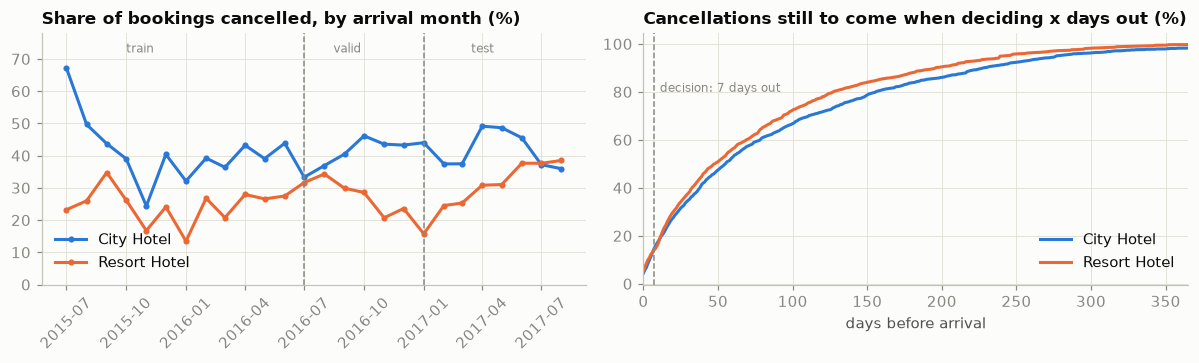

In [4]:
def show(df, fmt):
    """Display a table with per-column format strings (no Styler needed)."""
    out = df.copy()
    for c, f in fmt.items():
        if c in out:
            out[c] = out[c].map(lambda v, f=f: "" if pd.isna(v) else f.format(v))
    display(out)

month = bk.arrival.dt.to_period("M")
monthly = pd.DataFrame({"hotel": bk.hotel, "month": month, "y": y}).groupby(["month", "hotel"], observed=True).y.mean().unstack()
days_before = (bk.arrival - outcome.status_date).dt.days.where(y == 1)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
ax = axes[0]
for h in HOTELS:
    ax.plot(monthly.index.to_timestamp(), monthly[h] * 100, "-o", ms=3, lw=2, color=HCOL[h], label=h)
for x in [TRAIN_END, VALID_END]:
    ax.axvline(x, color=MUTED, ls="--", lw=1)
for x, lab_ in [("2015-10-01", "train"), ("2016-08-15", "valid"), ("2017-03-15", "test")]:
    ax.text(pd.Timestamp(x), 72, lab_, color=MUTED, fontsize=8)
ax.set_ylim(0, 78); ax.set_title("Share of bookings cancelled, by arrival month (%)"); ax.legend(loc="lower left")
ax.tick_params(axis="x", rotation=45)
ax = axes[1]
grid_days = np.arange(0, 366)
for h in HOTELS:
    d = days_before[(bk.hotel == h) & (y == 1)].values
    ax.plot(grid_days, [(d <= g).mean() * 100 for g in grid_days], lw=2, color=HCOL[h], label=h)
ax.axvline(DECISION_LEAD_DAYS, color=MUTED, ls="--", lw=1)
ax.text(DECISION_LEAD_DAYS + 4, 80, f"decision: {DECISION_LEAD_DAYS} days out", color=MUTED, fontsize=8)
ax.set_xlim(0, 365); ax.set_xlabel("days before arrival")
ax.set_title("Cancellations still to come when deciding x days out (%)"); ax.legend()
plt.tight_layout()

share_late = {h: (days_before[(bk.hotel == h) & (y == 1)] < DECISION_LEAD_DAYS).mean() for h in HOTELS}
print(f"median cancellation: {days_before.median():.0f} days before arrival · cancellations in the last {DECISION_LEAD_DAYS} days: "
      + " · ".join(f"{h} {v:.1%}" for h, v in share_late.items()))

In [5]:
def rate_by(col):
    t = pd.DataFrame({"hotel": bk.hotel, col: bk[col], "y": y}).groupby([col, "hotel"], observed=True).y.agg(["size", "mean"]).unstack()
    t.columns = [f"{h.split()[0]} {s}" for s, h in t.columns]
    return t[["City size", "City mean", "Resort size", "Resort mean"]].rename(
        columns={"City size": "City n", "City mean": "City rate", "Resort size": "Resort n", "Resort mean": "Resort rate"})

fmt = {"City n": "{:,.0f}", "City rate": "{:.1%}", "Resort n": "{:,.0f}", "Resort rate": "{:.1%}"}
print("cancellation rate by deposit type"); show(rate_by("deposit_type"), fmt)
print("cancellation rate by market segment"); show(rate_by("market_segment").sort_values("City n", ascending=False), fmt)

cancellation rate by deposit type


,City n,City rate,Resort n,Resort rate
deposit_type,,,,
No Deposit,"66,442",30.5%,"38,199",24.7%
Non Refund,"12,868",99.8%,"1,719",96.0%
Refundable,20,70.0%,142,15.5%


cancellation rate by market segment


,City n,City rate,Resort n,Resort rate
market_segment,,,,
Online TA,"38,748",37.4%,"17,729",35.2%
Offline TA/TO,"16,747",42.8%,"7,472",15.2%
Groups,"13,975",68.9%,"5,836",42.4%
Direct,"6,093",17.3%,"6,513",13.5%
Corporate,"2,986",21.5%,"2,309",15.2%
Complementary,542,11.8%,201,16.4%
Aviation,237,21.9%,,
Undefined,2,100.0%,,


**Two businesses:** the City loses 41.7 % of its bookings, the Resort 27.8 %. **Cancellations come early:** the median one is 54 days before arrival and only 13 % fall in the last week, so *will this booking ever cancel?* is not yet tonight's question (Section 4). **Labels mislead:** non-refundable bookings cancel 99.8 % of the time at the City and *Groups* 69 % — tour-operator blocks released in bulk.

# Part B — The given model

*Sections 3–5: read them, then package the code unchanged and reproduce its numbers (C2). You do not change the method.*

## 3 · The cancellation model: booking-time features, forward in time, gated per hotel

*Part B · Given model · package `build_features`, `fit` and `per_hotel` unchanged and reproduce the per-hotel gate (C2, C4).*

The rule for every feature: **known when the booking enters the PMS**, when `POST /predict` is called. The file does not record when columns were written, so each is argued:

| Column(s) | Known at booking? |
|---|---|
| lead time, dates, stay, guests, meal, reserved room, deposit, segment, channel, agent, company, ADR, *earlier* bookings | yes — used |
| `days_in_waiting_list` | only at confirmation ⚠ |
| `assigned_room_type`, `booking_changes`, `required_car_parking_spaces`, `total_of_special_requests` | no — final values ⚠ |
| `country` | doubtful — completed at check-in for intermediated bookings ⚠ |
| `reservation_status`, `reservation_status_date` | no — the outcome ⚠ |

One LightGBM model for both hotels, trained on arrivals to June 2016. Two metrics per hotel: **AUPRC** against the hotel's base rate, and **expected ÷ realised cancellations** (summed probabilities against the count), which the overbooking decision consumes.

In [6]:
tr = bk.arrival < TRAIN_END
va = (bk.arrival >= TRAIN_END) & (bk.arrival < VALID_END)
te = (bk.arrival >= VALID_END) & (bk.arrival < TEST_END)
TOP_AGENTS = bk.loc[tr, "agent"].value_counts().index[:60]          # chosen on the training window only

def build_features(bk: pd.DataFrame) -> pd.DataFrame:
    X = pd.DataFrame(index=bk.index)
    X["hotel"] = bk.hotel
    X["lead_time"] = bk.lead_time
    X["arrival_month"] = bk.arrival.dt.month
    X["arrival_dow"] = bk.arrival.dt.day_of_week
    X["booked_dow"] = bk.booked.dt.day_of_week
    X["weekend_nights"], X["week_nights"] = bk.stays_in_weekend_nights, bk.stays_in_week_nights
    X["adults"], X["children"], X["babies"] = bk.adults, bk.children, bk.babies
    for c in ["meal", "market_segment", "distribution_channel", "reserved_room_type", "deposit_type", "customer_type"]:
        X[c] = bk[c]
    X["is_repeated_guest"] = bk.is_repeated_guest
    X["previous_cancellations"] = bk.previous_cancellations
    X["previous_bookings_not_canceled"] = bk.previous_bookings_not_canceled
    X["agent"] = pd.Categorical(bk.agent.astype(str).where(bk.agent.isin(TOP_AGENTS), "other"))
    X["has_company"] = (bk.company != "none").astype(int)
    X["adr"] = bk.adr
    return X

X = build_features(bk)
BASE = list(X.columns)
LGB_PARAMS = dict(n_estimators=300, learning_rate=0.06, num_leaves=31, min_child_samples=50, subsample=0.8,
                  subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0, random_state=SEED, verbose=-1,
                  n_jobs=1)   # one thread: faster than two on a shared laptop, and deterministic

def fit(cols, train=tr, X_=None):
    X_ = X if X_ is None else X_
    return lgb.LGBMClassifier(**LGB_PARAMS).fit(X_.loc[train, cols], y[train])

def per_hotel(p, mask):
    """AUPRC, ROC-AUC, base rate and expected ÷ realised cancellations for each hotel."""
    yv, hv, rows = y[mask].values, bk.loc[mask, "hotel"].astype(str).values, {}
    for h in HOTELS + ["both (pooled)"]:
        s = (hv == h) if h in HOTELS else np.ones(len(yv), bool)
        if s.sum() and yv[s].sum():
            rows[h] = {"AUPRC": average_precision_score(yv[s], p[s]), "ROC-AUC": roc_auc_score(yv[s], p[s]),
                       "base rate": yv[s].mean(), "expected ÷ realised": p[s].sum() / yv[s].sum()}
    return pd.DataFrame(rows).T

for name, m_ in [("train", tr), ("valid", va), ("test", te)]:
    print(f"{name:5s} {m_.sum():6,} bookings · " + " · ".join(
        f"{h} {int((m_ & (bk.hotel == h)).sum()):,} ({y[m_ & (bk.hotel == h)].mean():.1%} cancelled)" for h in HOTELS))

t0 = time.time()
m_base = fit(BASE)
p_all = m_base.predict_proba(X[BASE])[:, 1]          # one score per booking; only valid/test rows are evaluated
p_te = p_all[te.values]
res_base = per_hotel(p_te, te)
sep = {}
for h in HOTELS:                                      # the alternative: one model per hotel
    hm = bk.hotel == h
    m_h = fit([c for c in BASE if c != "hotel"], train=tr & hm)
    sep[h] = per_hotel(m_h.predict_proba(X.loc[te & hm, [c for c in BASE if c != "hotel"]])[:, 1], te & hm).loc[h]
res = pd.concat({"pooled model": res_base, "one model per hotel": pd.DataFrame(sep).T})
print(f"fitted in {time.time()-t0:.0f}s · test season Jan – Aug 2017")
show(res, {"AUPRC": "{:.3f}", "ROC-AUC": "{:.3f}", "base rate": "{:.1%}", "expected ÷ realised": "{:.2f}"})

train 49,157 bookings · City Hotel 31,623 (41.7% cancelled) · Resort Hotel 17,534 (25.2% cancelled)
valid 29,546 bookings · City Hotel 20,199 (40.8% cancelled) · Resort Hotel 9,347 (28.4% cancelled)
test  40,687 bookings · City Hotel 27,508 (42.5% cancelled) · Resort Hotel 13,179 (30.8% cancelled)


fitted in 7s · test season Jan – Aug 2017


AUPRC ROC-AUC base rate expected ÷ realised
pooled model        City Hotel     0.786   0.799     42.5%                0.91
                    Resort Hotel   0.628   0.780     30.8%                0.68
                    both (pooled)  0.749   0.794     38.7%                0.85
one model per hotel City Hotel     0.768   0.773     42.5%                0.90
                    Resort Hotel   0.612   0.771     30.8%                0.67

In [7]:
holdout = pd.concat([X.loc[te, BASE], y[te]], axis=1)
fingerprint = hashlib.sha256(pd.util.hash_pandas_object(holdout, index=True).values.tobytes()).hexdigest()
gate = res_base.loc[HOTELS, ["AUPRC", "expected ÷ realised"]].copy()
gate["AUPRC ≥"] = [GATE_MIN_AUPRC[h] for h in HOTELS]
gate["AUPRC ok"] = gate.AUPRC >= gate["AUPRC ≥"]
gate["calibration ok"] = gate["expected ÷ realised"].between(*CALIBRATION_BAND)
gate["gate"] = np.where(gate["AUPRC ok"] & gate["calibration ok"], "PASS", "FAIL")
print(f"holdout: {te.sum():,} bookings, arrivals Jan – Aug 2017 · SHA-256 {fingerprint[:16]}…")
show(gate, {"AUPRC": "{:.3f}", "expected ÷ realised": "{:.2f}", "AUPRC ≥": "{:.2f}"})

holdout: 40,687 bookings, arrivals Jan – Aug 2017 · SHA-256 ac37475750f8f24a…


,AUPRC,expected ÷ realised,AUPRC ≥,AUPRC ok,calibration ok,gate
City Hotel,0.786,0.91,0.70,True,True,PASS
Resort Hotel,0.628,0.68,0.55,True,False,FAIL


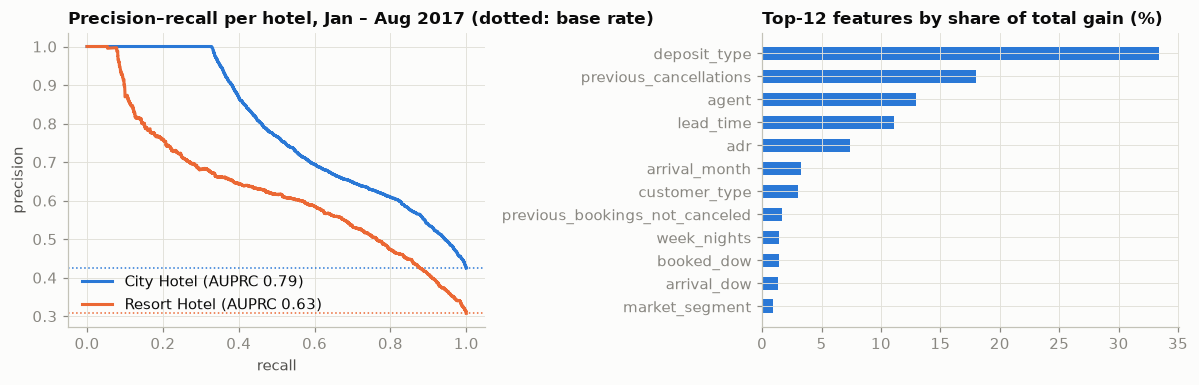

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
ax = axes[0]
yte, hte = y[te].values, bk.loc[te, "hotel"].astype(str).values
for h in HOTELS:
    s = hte == h
    pr, rc, _ = precision_recall_curve(yte[s], p_te[s])
    ax.plot(rc, pr, lw=2, color=HCOL[h], label=f"{h} (AUPRC {res_base.loc[h, 'AUPRC']:.2f})")
    ax.axhline(yte[s].mean(), color=HCOL[h], ls=":", lw=1)
ax.set_title("Precision–recall per hotel, Jan – Aug 2017 (dotted: base rate)"); ax.set_xlabel("recall"); ax.set_ylabel("precision")
ax.legend(loc="lower left")
ax = axes[1]
imp = pd.Series(m_base.booster_.feature_importance("gain"), index=BASE)
imp = (imp / imp.sum()).sort_values(ascending=False).head(12)
ax.barh(imp.index[::-1], imp.values[::-1] * 100, color=SERIES[0], height=0.6)
ax.set_title("Top-12 features by share of total gain (%)")
plt.tight_layout()

**Read the gate before the AUPRC.** Both hotels clear their AUPRC bar on 2017 (City 0.786 against a 42.5 % base rate; Resort 0.628 against 30.8 %), but the Resort model forecasts only 68 % of the cancellations: the Resort's rate rose from 25.2 % to 30.8 %. A model can rank well and miss the level. The gate refuses the Resort; the pooled figures (0.749, 0.85) would have hidden it. Separate models are slightly *worse* for both (0.768, 0.612): pool the training, gate per hotel. Deposit type carries a third of the gain, mostly as a marker of tour-operator blocks.

## 4 · Tonight's overbooking decision: from probabilities to rooms

*Part B · Given model · package `released_distribution`, `oversell`, `run_policies` and `summarise`; C3 asks you to own the walk and empty-room costs.*

The model answers *will this booking ever cancel?* The revenue manager asks *how many of tonight's books for 15 August will still cancel or not show?* Three steps:

1. **Reconstruct the books** `DECISION_LEAD_DAYS` before arrival: bookings entered earlier and not yet cancelled. The label is a *late cancellation* (on or after that day, or a no-show). This is the one legitimate use of `reservation_status_date` — knowing which bookings were live on a past date, never as a feature.
2. **Calibrate to the horizon** with per-hotel Platt scaling on the Jul – Sep 2016 nights. Bookings identical in every attribute (night, entry day, agent, price) form a **block that cancels together**.
3. **Choose like a newsvendor.** Overselling `q` rooms costs W = `WALK_COST_EUR` per guest walked when fewer than `q` rooms come back, and the night's room value R (median ADR on the books minus `VARIABLE_COST_EUR`) per room left empty when more come back. The cheapest `q` is the smallest whose probability of covering the releases reaches R ÷ (R + W): 0.28 on a typical City night.
4. **Choose on validation, report once.** Ten candidates (no overbooking; flat rates; the model with and without blocks, and re-levelled over the last 4, 8 or 12 weeks of matured nights) are compared on Oct – Dec 2016. The cheapest per hotel is frozen and run once on 2017.

In [9]:
h = DECISION_LEAD_DAYS
decision = bk.arrival - pd.Timedelta(days=h)
on_books = (bk.booked < decision) & ((y == 0) | (outcome.status_date >= decision))
late = ((y == 1) & (outcome.status_date >= decision)).astype(int)
GROUP_KEY = ["hotel", "arrival", "booked", "market_segment", "distribution_channel", "deposit_type", "agent", "company",
             "reserved_room_type", "customer_type", "meal", "adults", "children", "adr",
             "stays_in_weekend_nights", "stays_in_week_nights"]
snap = bk.loc[on_books, ["hotel", "arrival", "adr", "market_segment", "deposit_type", "agent"]].copy()
snap["hotel"] = snap.hotel.astype(str)
snap["y"], snap["p_booking"] = late[on_books], p_all[on_books.values]
snap["block"] = bk.loc[on_books].groupby(GROUP_KEY, observed=True, dropna=False).ngroup()
blocks = snap.groupby("block").y.agg(["size", "mean"])
multi = blocks[blocks["size"] > 1]
print(f"on the books {h} days before arrival: {len(snap):,} bookings · late-cancellation rate "
      + " · ".join(f"{hh} {snap.y[snap.hotel == hh].mean():.1%}" for hh in HOTELS))
print(f"multi-room blocks: {len(multi):,} holding {multi['size'].sum()/len(snap):.0%} of bookings and "
      f"{snap.y[snap.block.isin(multi.index)].sum()/snap.y.sum():.0%} of late cancellations · "
      f"blocks whose rooms all share one outcome: {((multi['mean'] == 0) | (multi['mean'] == 1)).mean():.0%}")

def logit(p):
    p = np.clip(p, 1e-4, 1 - 1e-4)
    return np.log(p / (1 - p))

snap["p_cal"] = np.nan
PLATT, FLAT_RATE = {}, {}
for hh in HOTELS:
    s = snap.hotel == hh
    v = s & (snap.arrival >= TRAIN_END) & (snap.arrival < CALIB_END)          # Jul – Sep 2016 only
    PLATT[hh] = LogisticRegression().fit(logit(snap.loc[v, "p_booking"]).to_frame("z"), snap.loc[v, "y"])
    snap.loc[s, "p_cal"] = PLATT[hh].predict_proba(logit(snap.loc[s, "p_booking"]).to_frame("z"))[:, 1]
    FLAT_RATE[hh] = snap.loc[v, "y"].mean()

# trailing re-levelling: realised ÷ expected over the arrival nights that had matured before each decision day
nightly = snap.groupby(["hotel", "arrival"]).agg(y=("y", "sum"), p=("p_cal", "sum"), n=("y", "size"))
keys = pd.MultiIndex.from_arrays([snap.hotel, snap.arrival])
for w in RECAL_WEEKS_GRID:
    trail = {}
    for hh in HOTELS:
        d = nightly.loc[hh].reindex(pd.date_range(WINDOW_START, WINDOW_END - pd.Timedelta(days=1)), fill_value=0)
        r = d.rolling(7 * w, min_periods=7).sum().shift(h + 1)     # only nights that arrived before the decision day
        trail[hh] = pd.DataFrame({"factor": r.y / r.p, "rate": r.y / r.n})
    trail = pd.concat(trail, names=["hotel", "arrival"]).replace([np.inf, -np.inf], np.nan)
    snap[f"relevel_{w}"] = trail.factor.reindex(keys).fillna(1.0).values
    snap[f"rate_{w}"] = trail.rate.reindex(keys).values

on the books 7 days before arrival: 61,761 bookings · late-cancellation rate City Hotel 8.6% · Resort Hotel 4.5%
multi-room blocks: 5,402 holding 35% of bookings and 43% of late cancellations · blocks whose rooms all share one outcome: 94%


In [10]:
def released_distribution(p, n):
    """P(k rooms released) when block i holds n_i rooms and cancels, as one, with probability p_i."""
    dist = np.zeros(int(n.sum()) + 1); dist[0] = 1.0
    for pi, ni in zip(p, n):
        nxt = dist * (1 - pi)
        nxt[ni:] += dist[:len(dist) - ni] * pi
        dist = nxt
    return dist

def oversell(dist, empty_cost, walk_cost=WALK_COST_EUR):
    """Newsvendor: the smallest q with P(released ≤ q) ≥ empty / (empty + walk)."""
    return int(np.searchsorted(np.cumsum(dist), empty_cost / (empty_cost + walk_cost) - 1e-12))

# each candidate maps a night's bookings g (and its blocks b) to cancellation probabilities and block sizes
POLICIES = {"no overbooking": None,
            "flat rate (Jul – Sep 2016)": lambda g, b: (np.full(len(g), FLAT_RATE[g.hotel.iat[0]]), None),
            **{f"flat rate (trailing {w} wk)": (lambda g, b, w=w: (np.full(len(g), g[f"rate_{w}"].iat[0]), None))
               for w in RECAL_WEEKS_GRID},
            "model": lambda g, b: (g.p_cal.values, None),
            "model + blocks": lambda g, b: (b.p.values, b.n.values),
            **{f"model + blocks + re-level {w} wk": (lambda g, b, w=w: (np.clip(b.p.values * b[f"f_{w}"].values, 0, 1), b.n.values))
               for w in RECAL_WEEKS_GRID}}
BLOCK_AGG = {"p": ("p_cal", "mean"), "n": ("p_cal", "size"), **{f"f_{w}": (f"relevel_{w}", "first") for w in RECAL_WEEKS_GRID}}

def run_policies(nights, policies, empty_cost_fn, eval_cost_fn=None):
    """Decide q per night with empty_cost_fn; cost the night with eval_cost_fn (the night's true room value)."""
    eval_cost_fn = eval_cost_fn or empty_cost_fn
    rows = []
    for (hh, night), g in nights.groupby(["hotel", "arrival"]):
        b = g.groupby("block").agg(**BLOCK_AGG)
        Rd, R, X_ = empty_cost_fn(g), eval_cost_fn(g), int(g.y.sum())
        for name, fn in policies.items():
            q, expected = 0, 0.0
            if fn is not None:
                p, n = fn(g, b)
                dist = released_distribution(p, np.ones(len(p), int) if n is None else n)
                q, expected = oversell(dist, Rd), float(dist @ np.arange(len(dist)))
            rows.append({"hotel": hh, "night": night, "policy": name, "q": q, "expected": expected, "released": X_,
                         "walked": max(q - X_, 0), "empty": max(X_ - q, 0),
                         "cost": WALK_COST_EUR * max(q - X_, 0) + R * max(X_ - q, 0)})
    return pd.DataFrame(rows)

def summarise(pol):
    t = pol.groupby(["hotel", "policy"], sort=False).agg(
        oversold=("q", "mean"), expected=("expected", "mean"), came_back=("released", "mean"), walked=("walked", "mean"),
        empty=("empty", "mean"), cost_per_night=("cost", "mean"), cost_total=("cost", "sum"))
    none = t.xs("no overbooking", level="policy").cost_total
    t["saving vs none (€)"] = none.reindex(t.index.get_level_values(0)).values - t.cost_total.values
    return t.drop(columns="cost_total")

FMT = {"oversold": "{:.2f}", "expected": "{:.2f}", "came_back": "{:.2f}", "walked": "{:.2f}", "empty": "{:.2f}",
       "cost_per_night": "€{:,.0f}", "saving vs none (€)": "{:+,.0f}"}
night_cost = lambda g: max(g.adr.median() - VARIABLE_COST_EUR, 0.0)

# 1 · choose, per hotel, on the selection months (Oct – Dec 2016): the lowest cost per night wins
t0 = time.time()
select_nights = snap[(snap.arrival >= CALIB_END) & (snap.arrival < VALID_END)]
sel = summarise(run_policies(select_nights, POLICIES, night_cost))
CHOSEN = {hh: sel.loc[hh].cost_per_night.idxmin() for hh in HOTELS}
sel["chosen"] = ["◀" if CHOSEN[hh] == p_ else "" for hh, p_ in sel.index]
print(f"selection months Oct – Dec 2016: {select_nights.groupby(['hotel', 'arrival']).ngroups} hotel-nights, "
      f"{len(POLICIES)} candidates, {time.time()-t0:.0f}s · chosen: " + " · ".join(f"{hh} → {p_}" for hh, p_ in CHOSEN.items()))
show(sel, FMT)

selection months Oct – Dec 2016: 184 hotel-nights, 10 candidates, 3s · chosen: City Hotel → flat rate (Jul – Sep 2016) · Resort Hotel → model + blocks + re-level 8 wk


oversold expected came_back walked empty cost_per_night saving vs none (€) chosen
hotel        policy                                                                                                           
City Hotel   no overbooking                      0.00     0.00      5.24   0.00  5.24           €423                 +0       
             flat rate (Jul – Sep 2016)          2.14     3.41      5.24   0.25  3.35           €329             +8,662      ◀
             flat rate (trailing 4 wk)           3.33     4.82      5.24   0.73  2.64           €393             +2,766       
             flat rate (trailing 8 wk)           3.02     4.51      5.24   0.55  2.77           €362             +5,632       
             flat rate (trailing 12 wk)          2.74     4.21      5.24   0.43  2.93           €344             +7,330       
             model                               1.35     2.48      5.24   0.11  4.00           €345             +7,212       
             model + blocks                      0.92     2.48      5.24   0.07  4.38           €366             +5,260       
             model + blocks + re-level 4 wk      2.60     4.73      5.24   0.47  3.11           €366             +5,255       
             model + blocks + re-level 8 wk      2.17     4.20      5.24   0.29  3.36           €346             +7,089       
             model + blocks + re-level 12 wk     1.86     3.71      5.24   0.22  3.60           €344             +7,343       
Resort Hotel no overbooking                      0.00     0.00      0.93   0.00  0.93            €42                 +0       
             flat rate (Jul – Sep 2016)          0.04     0.73      0.93   0.02  0.91            €45               -299       
             flat rate (trailing 4 wk)           0.10     0.83      0.93   0.05  0.89            €51               -824       
             flat rate (trailing 8 wk)           0.05     0.76      0.93   0.03  0.91            €48               -549       
             flat rate (trailing 12 wk)          0.04     0.72      0.93   0.02  0.91            €45               -299       
             model                               0.01     0.68      0.93   0.00  0.92            €41               +155       
             model + blocks                      0.01     0.68      0.93   0.00  0.92            €41               +155       
             model + blocks + re-level 4 wk      0.08     0.85      0.93   0.04  0.90            €49               -656       
             model + blocks + re-level 8 wk      0.02     0.77      0.93   0.00  0.91            €39               +303      ◀
             model + blocks + re-level 12 wk     0.02     0.72      0.93   0.00  0.91            €39               +303

In [11]:
# 2 · the chosen policies, frozen, reported once on the 2017 season (the holdout), against no overbooking
test_nights = snap[(snap.arrival >= VALID_END) & (snap.arrival < TEST_END)]
pol = pd.concat([run_policies(test_nights[test_nights.hotel == hh], {"no overbooking": None, CHOSEN[hh]: POLICIES[CHOSEN[hh]]},
                              night_cost) for hh in HOTELS])
print(f"2017, per night, a week out: "
      + " · ".join(f"{hh} {test_nights[test_nights.hotel == hh].groupby('arrival').size().mean():.0f} on the books, "
                   f"{test_nights.y[test_nights.hotel == hh].mean():.1%} released late" for hh in HOTELS)
      + f" · walk cost €{WALK_COST_EUR:.0f}")
R_typ = {hh: test_nights[test_nights.hotel == hh].groupby("arrival").adr.median().median() - VARIABLE_COST_EUR for hh in HOTELS}
print("typical empty-room cost and critical ratio R/(R+W): "
      + " · ".join(f"{hh} €{R_typ[hh]:.0f} → {R_typ[hh] / (R_typ[hh] + WALK_COST_EUR):.2f}" for hh in HOTELS))
show(summarise(pol), FMT)

2017, per night, a week out: City Hotel 58 on the books, 5.6% released late · Resort Hotel 28 on the books, 4.5% released late · walk cost €250
typical empty-room cost and critical ratio R/(R+W): City Hotel €96 → 0.28 · Resort Hotel €59 → 0.19


oversold expected came_back walked empty cost_per_night saving vs none (€)
hotel        policy                                                                                                   
City Hotel   no overbooking                     0.00     0.00      3.22   0.00  3.22           €279                 +0
             flat rate (Jul – Sep 2016)         2.48     3.73      3.22   0.63  1.37           €264             +3,457
Resort Hotel no overbooking                     0.00     0.00      1.26   0.00  1.26            €98                 +0
             model + blocks + re-level 8 wk     0.31     1.29      1.26   0.10  1.05            €96               +458

,policy,on the books,rooms in blocks,expected releases,P(no release),empty-room cost €,oversell q*,P(walk anyone),cost of q*±1 vs q*,released (hindsight)
City Hotel,flat rate (Jul – Sep 2016),66,16,4.27,1%,€105,3,19%,+€37,5
Resort Hotel,model + blocks + re-level 8 wk,15,2,0.46,65%,€189,0,0%,+€95,0


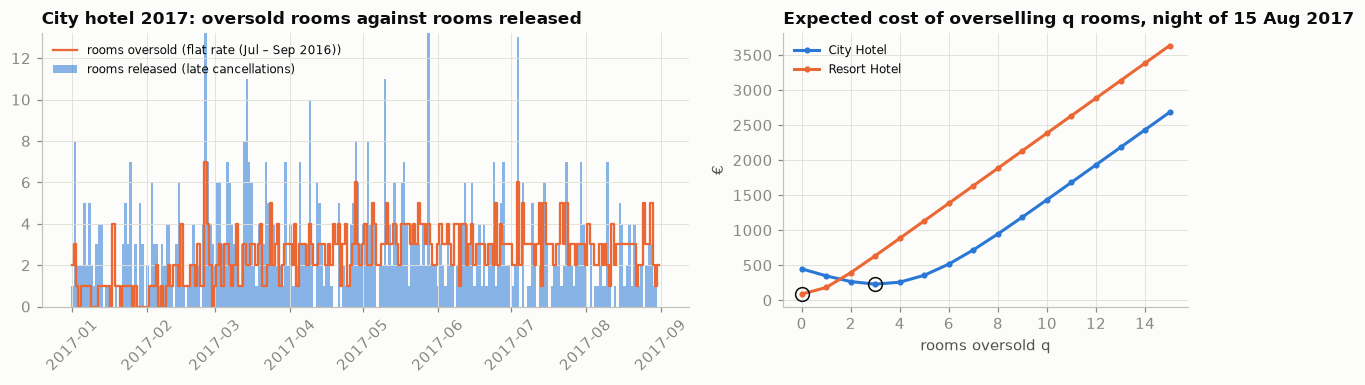

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [1.6, 1]})
ax = axes[0]
c = pol[(pol.hotel == "City Hotel") & (pol.policy == CHOSEN["City Hotel"])].set_index("night")
ax.bar(c.index, c.released, width=1, color=SERIES[0], alpha=0.55, label="rooms released (late cancellations)")
ax.step(c.index, c.q, where="mid", color=SERIES[1], lw=1.5, label=f"rooms oversold ({CHOSEN['City Hotel']})")
ax.set_ylim(0, max(12, np.percentile(c.released, 98) * 1.3))
ax.set_title("City hotel 2017: oversold rooms against rooms released"); ax.legend(loc="upper left", fontsize=8)
ax.tick_params(axis="x", rotation=45)
ax = axes[1]
night = TONIGHT + pd.Timedelta(days=h)
tonight_rows = {}
for hh in HOTELS:
    g = snap[(snap.hotel == hh) & (snap.arrival == night)]
    b = g.groupby("block").agg(**BLOCK_AGG)
    fn = POLICIES[CHOSEN[hh]] or POLICIES[f"model + blocks + re-level {RECAL_WEEKS_GRID[1]} wk"]   # curve only, if none chosen
    p, n = fn(g, b)
    dist = released_distribution(p, np.ones(len(p), int) if n is None else n); R = night_cost(g); k = np.arange(len(dist))
    qs = np.arange(0, 16)
    exp_cost = [WALK_COST_EUR * (np.clip(q - k, 0, None) @ dist) + R * (np.clip(k - q, 0, None) @ dist) for q in qs]
    q_star = oversell(dist, R) if POLICIES[CHOSEN[hh]] is not None else 0
    ax.plot(qs, exp_cost, "-o", ms=3, lw=2, color=HCOL[hh], label=hh)
    ax.plot([q_star], [exp_cost[q_star]], "o", ms=9, mfc="none", mec=INK)
    tonight_rows[hh] = {"policy": CHOSEN[hh], "on the books": len(g), "rooms in blocks": int(g.groupby("block").size().pipe(lambda s_: s_[s_ > 1].sum())),
                        "expected releases": float(dist @ k), "P(no release)": dist[0], "empty-room cost €": R,
                        "oversell q*": q_star, "P(walk anyone)": float(dist[:q_star].sum()),
                        "cost of q*±1 vs q*": max(exp_cost[max(q_star - 1, 0)], exp_cost[q_star + 1]) - exp_cost[q_star],
                        "released (hindsight)": int(g.y.sum())}
ax.set_title(f"Expected cost of overselling q rooms, night of {night:%d %b %Y}"); ax.set_xlabel("rooms oversold q"); ax.set_ylabel("€")
ax.set_xticks(qs[::2])
ax.legend(fontsize=8)
plt.tight_layout()
show(pd.DataFrame(tonight_rows).T, {"on the books": "{:.0f}", "rooms in blocks": "{:.0f}", "expected releases": "{:.2f}",
                                    "P(no release)": "{:.0%}", "empty-room cost €": "€{:.0f}", "oversell q*": "{:.0f}",
                                    "P(walk anyone)": "{:.0%}", "cost of q*±1 vs q*": "+€{:.0f}", "released (hindsight)": "{:.0f}"})

In [13]:
# Tonight's context pack: the facts a briefing (task S1) may use, and nothing else
g = snap[snap.arrival == night]
g = g.assign(relevel=1.0)
for hh in HOTELS:                                   # the chosen policy's re-levelling, where it has one
    if "re-level" in CHOSEN[hh]:
        g.loc[g.hotel == hh, "relevel"] = g.loc[g.hotel == hh, f"relevel_{CHOSEN[hh].split()[-2]}"]
top = (g.groupby(["hotel", "block"]).agg(rooms=("y", "size"), segment=("market_segment", "first"), deposit=("deposit_type", "first"),
                                         agent=("agent", "first"), p=("p_cal", "mean"), relevel=("relevel", "first"))
       .assign(p=lambda d: (d.p * d.relevel).clip(upper=1), expected_rooms=lambda d: d.p * d.rooms)
       .drop(columns="relevel").sort_values("expected_rooms", ascending=False).head(5).reset_index().drop(columns="block"))
context_pack = {"batch_date": f"{TONIGHT:%Y-%m-%d}", "arrival_night": f"{night:%Y-%m-%d}", "walk_cost_eur": WALK_COST_EUR,
                "hotels": {hh: {k: (v if isinstance(v, str) else round(float(v), 3)) for k, v in r.items() if k != "released (hindsight)"}
                           for hh, r in tonight_rows.items()},
                "riskiest_blocks": top.round(3).to_dict(orient="records")}
for hh, r in tonight_rows.items():
    print(f"{hh}: {r['on the books']} bookings on the books for {night:%d %b}; about {r['expected releases']:.1f} rooms expected back; "
          f"oversell {r['oversell q*']} (chance of walking anyone {r['P(walk anyone)']:.0%}).")
show(top, {"p": "{:.2f}", "expected_rooms": "{:.2f}"})
print(f"context pack: {len(json.dumps(context_pack, default=str)):,} characters of JSON for the briefing prompt")

City Hotel: 66 bookings on the books for 15 Aug; about 4.3 rooms expected back; oversell 3 (chance of walking anyone 19%).
Resort Hotel: 15 bookings on the books for 15 Aug; about 0.5 rooms expected back; oversell 0 (chance of walking anyone 0%).


,hotel,rooms,segment,deposit,agent,p,expected_rooms
0,City Hotel,4,Online TA,No Deposit,9,0.11,0.42
1,City Hotel,2,Online TA,No Deposit,9,0.11,0.22
2,City Hotel,2,Online TA,No Deposit,9,0.10,0.21
3,City Hotel,2,Online TA,No Deposit,9,0.09,0.17
4,City Hotel,2,Direct,No Deposit,none,0.06,0.13


context pack: 1,344 characters of JSON for the briefing prompt


**Choosing (Oct – Dec 2016).** At the City every candidate beats doing nothing (€423 a night), and they sit close together: the flat Jul – Sep rate (€329) narrowly beats the model with blocks and 12-week re-levelling (€344). On this evidence a cancellation model does not count rooms better than the flat rule. At the Resort (0.9 rooms back a night) the 8-week re-levelling wins, tied with 12 weeks (€39 against €42).

**Reporting once (2017, 243 nights).** The City's flat rate oversells 2.5 rooms a night and walks 0.63 guests: €264 a night against €279 with no overbooking, €3.5k saved. It expects 3.7 rooms back for 3.2 because late cancellations fell (Section 6), which a monitor on its own expected ÷ realised would catch (task C5). The Resort saves €458 in eight months: not worth running.

**Tonight.** For 15 August the City has 66 bookings on the books; the flat rate expects 4.3 rooms back and oversells 3, with a 19 % chance of walking anyone (in the event, 5 came back). The cost curve is flat near its minimum — one room either way costs at most €37 more in expectation — so the answer is "about three", not a precise number (task C3). The Resort expects half a room: none. The last table is the *context pack*, the only facts a briefing may use (task S1).

## 5 · The traps ⚠

*Part B · Given model · read; C1 turns each trap into a test.*

Six shortcuts, each a better-looking number and a worse decision, measured naive against honest.

**Trap 1 — the outcome columns.** `reservation_status` *is* the label and its date is the cancellation day. As a feature (days from status date to arrival) it gives a perfect model:

In [14]:
print(pd.crosstab(outcome.reservation_status, y.rename("is_canceled")))
X_leak = X.copy()
X_leak["status_days_before_arrival"] = (bk.arrival - outcome.status_date).dt.days
m_leak = fit(BASE + ["status_days_before_arrival"], X_=X_leak)
r_leak = per_hotel(m_leak.predict_proba(X_leak.loc[te, BASE + ["status_days_before_arrival"]])[:, 1], te)
show(pd.concat({"honest": res_base, "with the status date ⚠": r_leak}).loc[:, ["AUPRC", "expected ÷ realised"]],
     {"AUPRC": "{:.3f}", "expected ÷ realised": "{:.2f}"})

is_canceled             0      1
reservation_status              
Canceled                0  43017
Check-Out           75166      0
No-Show                 0   1207


AUPRC expected ÷ realised
honest                 City Hotel     0.786                0.91
                       Resort Hotel   0.628                0.68
                       both (pooled)  0.749                0.85
with the status date ⚠ City Hotel     1.000                1.00
                       Resort Hotel   1.000                1.00
                       both (pooled)  1.000                1.00

It happens when a pipeline selects "all columns except the label". The fix: the outcome lives in its own frame (Section 1), plus a test.

**Trap 2 — the random split.** Shuffle all bookings 70/30:

In [15]:
idx = np.arange(len(bk))
i_tr, i_te = train_test_split(idx, test_size=0.3, random_state=SEED, stratify=y)
rtr, rte = pd.Series(False, index=bk.index), pd.Series(False, index=bk.index)
rtr.iloc[i_tr], rte.iloc[i_te] = True, True
m_rand = fit(BASE, train=rtr)
r_rand = per_hotel(m_rand.predict_proba(X.loc[rte, BASE])[:, 1], rte)
row_key = pd.util.hash_pandas_object(raw.drop(columns=["booked"]), index=False)
twin_random = row_key[rte].isin(set(row_key[rtr])).mean()
twin_forward = row_key[te].isin(set(row_key[tr | va])).mean()
print(f"test rows with an identical row in training: random split {twin_random:.1%} · forward split {twin_forward:.1%}")
show(pd.concat({"forward in time (honest)": res_base, "random 70/30 ⚠": r_rand}).loc[:, ["AUPRC", "ROC-AUC", "expected ÷ realised"]],
     {"AUPRC": "{:.3f}", "ROC-AUC": "{:.3f}", "expected ÷ realised": "{:.2f}"})

test rows with an identical row in training: random split 30.7% · forward split 0.0%


AUPRC ROC-AUC expected ÷ realised
forward in time (honest) City Hotel     0.786   0.799                0.91
                         Resort Hotel   0.628   0.780                0.68
                         both (pooled)  0.749   0.794                0.85
random 70/30 ⚠           City Hotel     0.879   0.889                1.00
                         Resort Hotel   0.749   0.856                1.00
                         both (pooled)  0.850   0.882                1.00

The random split adds about 0.1 AUPRC per hotel (City 0.879 against 0.786; Resort 0.749 against 0.628) and looks perfectly calibrated (1.00): its test rows share the training seasons, and 30.7 % have an exact twin (a room of the same block) in training, against none forward.

**Trap 3 — columns written after the booking.** Guests who never arrive cannot change rooms, park a car, or keep adding requests:

In [16]:
LATER = {
    "room_changed": (bk.assigned_room_type.astype(str) != bk.reserved_room_type.astype(str)).astype(int),   # assigned ≠ reserved
    "booking_changes": bk.booking_changes,
    "required_car_parking_spaces": bk.required_car_parking_spaces,
    "total_of_special_requests": bk.total_of_special_requests,
    "days_in_waiting_list": bk.days_in_waiting_list,
}
X_later = X.copy()
rows = []
for name, col in LATER.items():
    X_later[name] = col
    on = col > 0
    r = per_hotel(fit(BASE + [name], X_=X_later).predict_proba(X_later.loc[te, BASE + [name]])[:, 1], te)
    rows.append({"column": {"room_changed": "assigned ≠ reserved room"}.get(name, name), "bookings with value > 0": int(on.sum()), "cancel rate if > 0": y[on].mean(),
                 "cancel rate if 0": y[~on].mean(), "City AUPRC": r.loc["City Hotel", "AUPRC"], "Resort AUPRC": r.loc["Resort Hotel", "AUPRC"]})
cols_later = list(LATER)
r_all = per_hotel(fit(BASE + cols_later, X_=X_later).predict_proba(X_later.loc[te, BASE + cols_later])[:, 1], te)
rows.append({"column": "all five ⚠", "City AUPRC": r_all.loc["City Hotel", "AUPRC"], "Resort AUPRC": r_all.loc["Resort Hotel", "AUPRC"]})
rows.append({"column": "honest baseline", "City AUPRC": res_base.loc["City Hotel", "AUPRC"], "Resort AUPRC": res_base.loc["Resort Hotel", "AUPRC"]})
show(pd.DataFrame(rows).set_index("column"), {"bookings with value > 0": "{:,.0f}", "cancel rate if > 0": "{:.1%}",
                                              "cancel rate if 0": "{:.1%}", "City AUPRC": "{:.3f}", "Resort AUPRC": "{:.3f}"})

,bookings with value > 0,cancel rate if > 0,cancel rate if 0,City AUPRC,Resort AUPRC
column,,,,,
assigned ≠ reserved room,"14,917",5.4%,41.6%,0.790,0.658
booking_changes,"18,076",15.7%,40.9%,0.793,0.652
required_car_parking_spaces,"7,416",0.0%,39.5%,0.786,0.680
total_of_special_requests,"49,072",21.7%,47.7%,0.818,0.679
days_in_waiting_list,"3,698",63.8%,36.2%,0.783,0.635
all five ⚠,,,,0.831,0.748
honest baseline,,,,0.786,0.628


Not one of the 7,416 bookings with a parking space was cancelled; guests moved to another room type cancel at 5.4 % against 41.6 %. Together the five lift AUPRC (City 0.831, Resort 0.748) with information the PMS lacks at `POST /predict` time. `days_in_waiting_list` is borderline — known at confirmation — and worthless here (City 0.783 against 0.786).

**Trap 4 — `country`, the feature that dominates.** Look at *which* bookings are Portuguese:

In [17]:
is_prt = (bk.country.astype(str) == "PRT")
seg = pd.DataFrame({"segment": bk.market_segment.astype(str), "prt": is_prt, "y": y})
ev = seg[seg.segment.isin(["Offline TA/TO", "Groups", "Online TA", "Direct"])].groupby(["segment", "y"]).prt.mean().unstack()
ev.columns = ["PRT share · arrived", "PRT share · cancelled"]
yr = pd.DataFrame({"year": bk.arrival.dt.year, "prt": is_prt, "y": y}).groupby(["year", "y"]).prt.mean().unstack()
yr.columns = ["PRT share · arrived", "PRT share · cancelled"]
show(pd.concat([ev, yr.rename(index=lambda v: f"all segments · {v}")]), {c: "{:.0%}" for c in ev.columns})

X_cty = X.copy()
top_cty = bk.loc[tr, "country"].value_counts().index[:40]
X_cty["country"] = pd.Categorical(bk.country.astype(str).where(bk.country.isin(top_cty), "other"))
m_cty = fit(BASE + ["country"], X_=X_cty)
r_cty = per_hotel(m_cty.predict_proba(X_cty.loc[te, BASE + ["country"]])[:, 1], te)
gain_cty = pd.Series(m_cty.booster_.feature_importance("gain"), index=BASE + ["country"])
print(f"country's share of total gain: {gain_cty['country'] / gain_cty.sum():.0%} (rank {int((gain_cty > gain_cty['country']).sum()) + 1} of {len(gain_cty)})")
show(pd.concat({"honest (no country)": res_base, "with country ⚠": r_cty}).loc[:, ["AUPRC", "expected ÷ realised"]],
     {"AUPRC": "{:.3f}", "expected ÷ realised": "{:.2f}"})

,PRT share · arrived,PRT share · cancelled
Direct,44%,62%
Groups,29%,97%
Offline TA/TO,24%,98%
Online TA,18%,26%
all segments · 2015,41%,93%
all segments · 2016,27%,61%
all segments · 2017,22%,48%


country's share of total gain: 11% (rank 3 of 23)


AUPRC expected ÷ realised
honest (no country) City Hotel     0.786                0.91
                    Resort Hotel   0.628                0.68
                    both (pooled)  0.749                0.85
with country ⚠      City Hotel     0.809                0.80
                    Resort Hotel   0.628                0.49
                    both (pooled)  0.770                0.72

Cancelled *Offline TA/TO* bookings are 98 % "Portuguese" against 24 % of arrivals, *Groups* 97 % against 29 %, but *Online TA*, where guests type their details, 26 % against 18 %. Nationality behaves like a field completed at check-in, and the artefact fades (93 % of cancellations in 2015, 48 % in 2017). With country the City's AUPRC rises (0.809; third by gain) but the level collapses (0.80 City, 0.49 Resort): a 2015 recording habit. It is also sensitive (task E2). Keep it out.

**Trap 5 — one ADR for every night.** ADR is a price: it moves with the season (Resort median €47 in January, €180 in August) and with typing errors. The policy uses it as the value of an empty room:

In [18]:
out_night = bk.loc[bk.adr.idxmax()]
nb_ = bk[(bk.hotel == out_night.hotel) & (bk.arrival == out_night.arrival)].adr
print(f"ADR max €{bk.adr.max():,.0f} · min €{bk.adr.min():.2f} ({int((bk.adr < 0).sum())} negative) · zero-rate bookings {int((bk.adr == 0).sum()):,} · "
      f"dataset mean €{bk.adr.mean():.2f} (without the max €{bk.adr[bk.adr < bk.adr.max()].mean():.2f})")
print(f"the €{out_night.adr:,.0f} booking: {out_night.stays_in_weekend_nights + out_night.stays_in_week_nights} night, "
      f"{out_night.adults} adults, {out_night.market_segment}, cancelled {(outcome.status_date[bk.adr.idxmax()] - out_night.booked).days} days after it was made")
print(f"its night ({out_night.hotel}, {out_night.arrival:%d %b %Y}): mean ADR €{nb_.mean():.0f} with it, "
      f"€{nb_[nb_ < bk.adr.max()].mean():.0f} without, median €{nb_.median():.0f}")
FLAT_ADR = bk.adr.mean()
P5 = {hh: CHOSEN[hh] if POLICIES[CHOSEN[hh]] else f"model + blocks + re-level {RECAL_WEEKS_GRID[1]} wk" for hh in HOTELS}
rules = {"night's median ADR (honest)": night_cost, "one dataset-wide mean ADR ⚠": lambda g: FLAT_ADR - VARIABLE_COST_EUR}
runs5 = {name: pd.concat([run_policies(test_nights[test_nights.hotel == hh], {"no overbooking": None, P5[hh]: POLICIES[P5[hh]]},
                                       fn, eval_cost_fn=night_cost) for hh in HOTELS]) for name, fn in rules.items()}
q_by_rule = [r_[r_.policy != "no overbooking"].set_index(["hotel", "night"]).q for r_ in runs5.values()]
ratio = test_nights.groupby(["hotel", "arrival"]).adr.median().sub(VARIABLE_COST_EUR).clip(lower=0)
ratio = (ratio / (ratio + WALK_COST_EUR)).groupby(level=0).quantile([0.05, 0.95]).unstack()
flat_ratio = (FLAT_ADR - VARIABLE_COST_EUR) / (FLAT_ADR - VARIABLE_COST_EUR + WALK_COST_EUR)
print(f"critical ratio R/(R+W): one mean ADR gives {flat_ratio:.2f} every night; the night's median gives "
      + " · ".join(f"{hh} {ratio.loc[hh, 0.05]:.2f}–{ratio.loc[hh, 0.95]:.2f}" for hh in HOTELS) + " (5th–95th percentile of 2017 nights)")
print("2017 nights on which the oversell changes: "
      + " · ".join(f"{hh} {(q_by_rule[0][hh] != q_by_rule[1][hh]).mean():.0%}" for hh in HOTELS)
      + " · each hotel's chosen policy, costed at the night's own ADR")
cmp_adr = pd.concat({name: summarise(r_).drop("no overbooking", level="policy") for name, r_ in runs5.items()})
show(cmp_adr[["oversold", "walked", "empty", "cost_per_night", "saving vs none (€)"]], FMT)

ADR max €5,400 · min €-6.38 (1 negative) · zero-rate bookings 1,959 · dataset mean €101.83 (without the max €101.79)
the €5,400 booking: 1 night, 2 adults, Offline TA/TO, cancelled 0 days after it was made
its night (City Hotel, 25 Mar 2016): mean ADR €141 with it, €112 without, median €105


critical ratio R/(R+W): one mean ADR gives 0.25 every night; the night's median gives City Hotel 0.19–0.32 · Resort Hotel 0.08–0.43 (5th–95th percentile of 2017 nights)
2017 nights on which the oversell changes: City Hotel 25% · Resort Hotel 25% · each hotel's chosen policy, costed at the night's own ADR


oversold walked empty cost_per_night saving vs none (€)
                            hotel        policy                                                                                
night's median ADR (honest) City Hotel   flat rate (Jul – Sep 2016)         2.48   0.63  1.37           €264             +3,457
                            Resort Hotel model + blocks + re-level 8 wk     0.31   0.10  1.05            €96               +458
one dataset-wide mean ADR ⚠ City Hotel   flat rate (Jul – Sep 2016)         2.41   0.59  1.40           €259             +4,888
                            Resort Hotel model + blocks + re-level 8 wk     0.25   0.07  1.07           €101               -789

The €5,400 booking moves the dataset mean by four cents but its night's mean from €112 to €141: use medians. The season matters more: one mean ADR fixes the critical ratio at 0.25, the night's price moves it between 0.08 and 0.43 at the Resort, and the oversell changes on 25 % of nights. The naive rule turns the Resort's €458 saving into a €789 loss. At the City it happens to cost less (€259 against €264) because it undersells against a forecast running high: two errors cancelling. A cost constant comes from economics, not from outcomes.

**Trap 6 — the right probability at the wrong time.** Feed the booking-time probability, uncalibrated, into tonight's decision:

In [19]:
NAIVE = {"no overbooking": None, "booking-time probability ⚠": lambda g, b: (g.p_booking.values, None)}
show(summarise(run_policies(test_nights, NAIVE, night_cost)), FMT)

oversold expected came_back walked empty cost_per_night saving vs none (€)
hotel        policy                                                                                               
City Hotel   no overbooking                 0.00     0.00      3.22   0.00  3.22           €279                 +0
             booking-time probability ⚠    14.28    16.24      3.22  11.20  0.14         €2,808           -614,718
Resort Hotel no overbooking                 0.00     0.00      1.26   0.00  1.26            €98                 +0
             booking-time probability ⚠     3.73     5.16      1.26   2.64  0.17           €669           -138,623

It expects 16.2 rooms back at the City when 3.2 come back, walks 11.2 guests a night and costs €615k more than doing nothing over the season (Resort: €139k). Only 13 % of cancellations fall in the last week: a probability holds only for the population and moment it was calibrated on.

# Part C — Productionise it

*Sections 6–10: this is your assignment.*

## 6 · After deployment: the inputs drift, and the forecast drifts faster

*Part C · Productionise · what your monitoring plan must catch; reuse `psi_num`, `psi_cat` and `month_metrics` (C5).*

Freeze the June 2016 model and its Jul – Sep 2016 calibration and run them month by month, on Task 02's two clocks: **now**, the inputs, with PSI against the training season; **later**, AUPRC and expected ÷ realised, which exist only once the night has passed.

late-cancellation rate (on the books a week out), by quarter


q,2015Q3,2015Q4,2016Q1,2016Q2,2016Q3,2016Q4,2017Q1,2017Q2,2017Q3
hotel,,,,,,,,,
City Hotel,14.4%,8.8%,14.5%,10.6%,6.5%,9.9%,8.1%,5.2%,3.5%
Resort Hotel,3.4%,8.1%,8.1%,3.7%,2.6%,3.3%,5.6%,4.3%,3.8%


PSI by quarter, against Jul 2015 – Jun 2016


lead_time market_segment distribution_channel country deposit_type
hotel        quarter                                                                   
City Hotel   2016Q3       0.21           0.26                 0.01    0.29         0.06
             2016Q4       0.11           0.16                 0.01    0.18         0.01
             2017Q1       0.18           0.27                 0.01    0.22         0.03
             2017Q2       0.27           0.18                 0.01    0.27         0.00
             2017Q3       0.44           0.56                 0.04    0.66         0.34
Resort Hotel 2016Q3       0.31           0.22                 0.08    0.12         0.05
             2016Q4       0.04           0.09                 0.03    0.13         0.03
             2017Q1       0.15           0.14                 0.04    0.08         0.05
             2017Q2       0.22           0.07                 0.06    0.27         0.04
             2017Q3       0.31           1.05                 0.12    0.34         0.20

PSI of Jul – Aug 2017 against Jul – Sep 2015 (same season)


,lead_time,market_segment,country
City Hotel,0.52,1.45,1.55
Resort Hotel,0.30,0.51,0.28


2017 by arrival month (frozen model, retrained model, and the frozen 7-day forecast's expected ÷ realised)


,AUPRC frozen · City,AUPRC frozen · Resort,AUPRC retrained · City,AUPRC retrained · Resort,late exp/real (frozen) · City,late exp/real (frozen) · Resort
month,,,,,,
2017-01,0.86,0.51,0.87,0.50,0.89,0.48
2017-02,0.76,0.62,0.76,0.64,0.72,0.38
2017-03,0.80,0.66,0.80,0.65,1.11,0.70
2017-04,0.84,0.67,0.86,0.69,1.65,0.66
2017-05,0.84,0.70,0.85,0.72,1.40,0.58
2017-06,0.84,0.66,0.85,0.67,1.75,0.69
2017-07,0.62,0.56,0.68,0.62,1.88,0.76
2017-08,0.55,0.60,0.60,0.71,2.10,0.60


label delay of the booking-time score = lead time; median in the test season: City Hotel 87 days · Resort Hotel 66 days


AUPRC expected ÷ realised
frozen Jun 2016    City Hotel     0.786                0.91
                   Resort Hotel   0.628                0.68
                   both (pooled)  0.749                0.85
retrained Dec 2016 City Hotel     0.806                0.98
                   Resort Hotel   0.668                0.79
                   both (pooled)  0.774                0.93

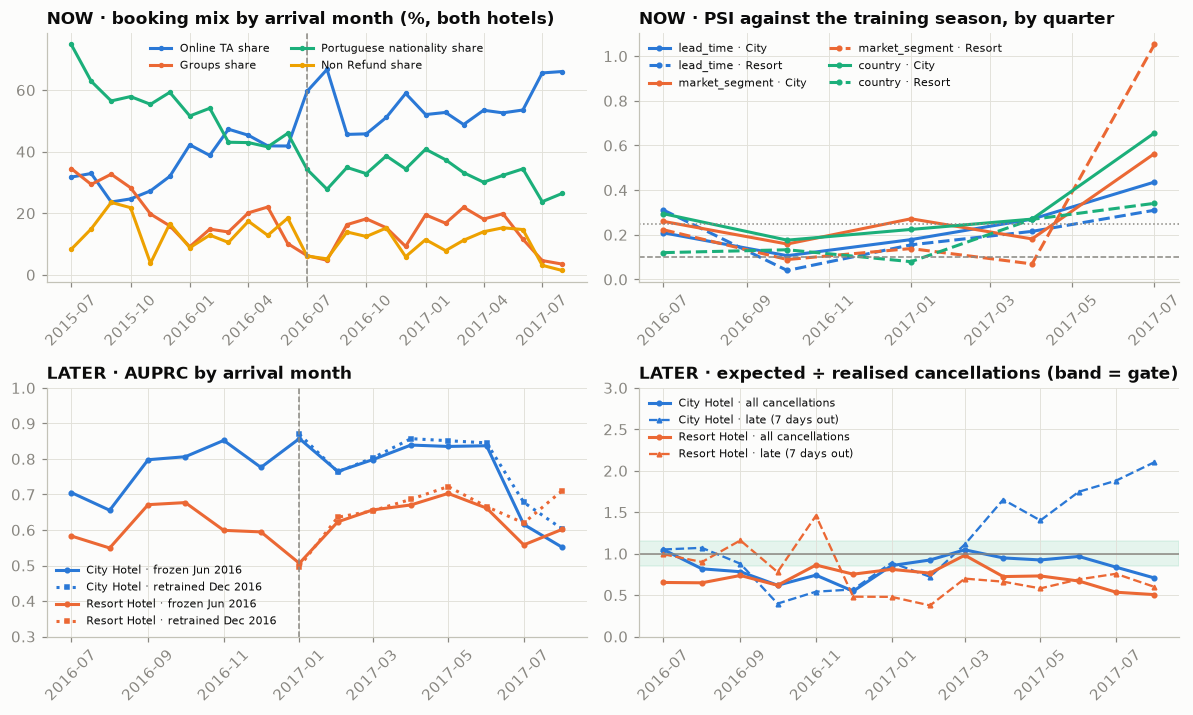

In [20]:
def psi_num(ref, cur, bins=10):
    edges = np.unique(np.quantile(ref, np.linspace(0, 1, bins + 1))); edges[0], edges[-1] = -np.inf, np.inf
    r = np.histogram(ref, edges)[0] / len(ref) + 1e-6
    c = np.histogram(cur, edges)[0] / len(cur) + 1e-6
    return float(np.sum((c - r) * np.log(c / r)))

def psi_cat(ref, cur):
    r = ref.value_counts(normalize=True); c = cur.value_counts(normalize=True)
    idx_ = r.index.union(c.index)
    r, c = r.reindex(idx_, fill_value=0) + 1e-4, c.reindex(idx_, fill_value=0) + 1e-4
    return float(np.sum((c - r) * np.log(c / r)))

cty20 = bk.country.astype(str).where(bk.country.isin(bk.loc[tr, "country"].value_counts().index[:20]), "other")
quarter = bk.arrival.dt.to_period("Q")
psi_rows = []
for hh in HOTELS:
    ref = tr & (bk.hotel == hh)
    for qtr in sorted(quarter[~tr].unique()):
        cur = (quarter == qtr) & (bk.hotel == hh)
        psi_rows.append({"hotel": hh, "quarter": str(qtr), "lead_time": psi_num(bk.lead_time[ref], bk.lead_time[cur]),
                         "market_segment": psi_cat(bk.market_segment[ref].astype(str), bk.market_segment[cur].astype(str)),
                         "distribution_channel": psi_cat(bk.distribution_channel[ref].astype(str), bk.distribution_channel[cur].astype(str)),
                         "country": psi_cat(cty20[ref], cty20[cur]),
                         "deposit_type": psi_cat(bk.deposit_type[ref].astype(str), bk.deposit_type[cur].astype(str))})
psi_tbl = pd.DataFrame(psi_rows).set_index(["hotel", "quarter"])

# later: the frozen model and a model retrained on everything up to December 2016, month by month
m_retrain = fit(BASE, train=tr | va)
p_retrain = m_retrain.predict_proba(X[BASE])[:, 1]
mon = pd.DataFrame({"hotel": bk.hotel.astype(str), "month": month, "y": y, "p": p_all, "p_re": p_retrain,
                    "online": (bk.market_segment == "Online TA"), "groups": (bk.market_segment == "Groups"),
                    "prt": is_prt, "nonref": (bk.deposit_type == "Non Refund"), "lead": bk.lead_time})
after = mon[~tr.values]
def month_metrics(d):
    return pd.Series({"AUPRC frozen": average_precision_score(d.y, d.p), "AUPRC retrained": average_precision_score(d.y, d.p_re),
                      "exp/real frozen": d.p.sum() / d.y.sum(), "exp/real retrained": d.p_re.sum() / d.y.sum()})
later = after.groupby(["hotel", "month"]).apply(month_metrics, include_groups=False)
late_m = snap.assign(month=snap.arrival.dt.to_period("M")).groupby(["hotel", "month"]).agg(late_rate=("y", "mean"), late_exp=("p_cal", "sum"), late_real=("y", "sum"))
late_m["late exp/real (frozen)"] = late_m.late_exp / late_m.late_real
inputs_m = mon.groupby("month")[["online", "groups", "prt", "nonref"]].mean()

fig, axes = plt.subplots(2, 2, figsize=(11, 6.6))
ax = axes[0, 0]
t_ = inputs_m.index.to_timestamp()
for col, lab_, color in [("online", "Online TA share", SERIES[0]), ("groups", "Groups share", SERIES[1]),
                         ("prt", "Portuguese nationality share", SERIES[2]), ("nonref", "Non Refund share", SERIES[3])]:
    ax.plot(t_, inputs_m[col] * 100, "-o", ms=2.5, lw=2, color=color, label=lab_)
ax.axvline(TRAIN_END, color=MUTED, ls="--", lw=1)
ax.set_title("NOW · booking mix by arrival month (%, both hotels)"); ax.legend(fontsize=7, ncol=2); ax.tick_params(axis="x", rotation=45)
ax = axes[0, 1]
for col, color in [("lead_time", SERIES[0]), ("market_segment", SERIES[1]), ("country", SERIES[2])]:
    for hh, ls in [("City Hotel", "-"), ("Resort Hotel", "--")]:
        s = psi_tbl.loc[hh, col]
        ax.plot(pd.PeriodIndex(s.index, freq="Q").to_timestamp(), s.values, ls, marker="o", ms=3, lw=2, color=color,
                label=f"{col} · {hh.split()[0]}")
ax.axhline(0.10, color=MUTED, ls="--", lw=1); ax.axhline(0.25, color=MUTED, ls=":", lw=1)
ax.set_title("NOW · PSI against the training season, by quarter"); ax.legend(fontsize=7, ncol=2); ax.tick_params(axis="x", rotation=45)
ax = axes[1, 0]
for hh in HOTELS:
    s = later.loc[hh]
    ax.plot(s.index.to_timestamp(), s["AUPRC frozen"], "-o", ms=3, lw=2, color=HCOL[hh], label=f"{hh} · frozen Jun 2016")
    s2 = s[s.index >= pd.Period("2017-01", "M")]
    ax.plot(s2.index.to_timestamp(), s2["AUPRC retrained"], ":", marker="s", ms=3, lw=2, color=HCOL[hh], label=f"{hh} · retrained Dec 2016")
ax.axvline(VALID_END, color=MUTED, ls="--", lw=1)
ax.set_ylim(0.3, 1.0); ax.set_title("LATER · AUPRC by arrival month"); ax.legend(fontsize=7); ax.tick_params(axis="x", rotation=45)
ax = axes[1, 1]
ax.axhspan(*CALIBRATION_BAND, color=SERIES[2], alpha=0.10)
for hh in HOTELS:
    s = later.loc[hh]
    ax.plot(s.index.to_timestamp(), s["exp/real frozen"], "-o", ms=3, lw=2, color=HCOL[hh], label=f"{hh} · all cancellations")
    s3 = late_m.loc[hh]
    s3 = s3[s3.index >= pd.Period("2016-07", "M")]
    ax.plot(s3.index.to_timestamp(), s3["late exp/real (frozen)"], "--", marker="^", ms=3, lw=1.5, color=HCOL[hh],
            label=f"{hh} · late ({h} days out)")
ax.axhline(1, color=MUTED, lw=1); ax.set_ylim(0, 3)
ax.set_title("LATER · expected ÷ realised cancellations (band = gate)"); ax.legend(fontsize=7); ax.tick_params(axis="x", rotation=45)
plt.tight_layout()

q_late = snap.assign(q=snap.arrival.dt.to_period("Q")).groupby(["hotel", "q"]).y.mean().unstack(0)
print("late-cancellation rate (on the books a week out), by quarter"); show(q_late.T, {c: "{:.1%}" for c in q_late.index})
print("PSI by quarter, against Jul 2015 – Jun 2016"); show(psi_tbl, {c: "{:.2f}" for c in psi_tbl.columns})
same_season = {}
for hh in HOTELS:      # the same summer two years earlier: what is left once the season is taken out
    ref, cur = (quarter == pd.Period("2015Q3", "Q")) & (bk.hotel == hh), (quarter == pd.Period("2017Q3", "Q")) & (bk.hotel == hh)
    same_season[hh] = {"lead_time": psi_num(bk.lead_time[ref], bk.lead_time[cur]),
                       "market_segment": psi_cat(bk.market_segment[ref].astype(str), bk.market_segment[cur].astype(str)),
                       "country": psi_cat(cty20[ref], cty20[cur])}
print("PSI of Jul – Aug 2017 against Jul – Sep 2015 (same season)"); show(pd.DataFrame(same_season).T, {c: "{:.2f}" for c in ["lead_time", "market_segment", "country"]})
tbl17 = later.join(late_m["late exp/real (frozen)"])
tbl17 = tbl17[tbl17.index.get_level_values("month") >= pd.Period("2017-01", "M")][["AUPRC frozen", "AUPRC retrained", "late exp/real (frozen)"]]
print("2017 by arrival month (frozen model, retrained model, and the frozen 7-day forecast's expected ÷ realised)")
tbl17 = tbl17.unstack(0).round(2)
tbl17.columns = [f"{m} · {h.split()[0]}" for m, h in tbl17.columns]
display(tbl17)
p_re_te = p_retrain[te.values]
print("label delay of the booking-time score = lead time; median in the test season: "
      + " · ".join(f"{hh} {bk.lead_time[te & (bk.hotel == hh)].median():.0f} days" for hh in HOTELS))
show(pd.concat({"frozen Jun 2016": res_base, "retrained Dec 2016": per_hotel(p_re_te, te)}).loc[:, ["AUPRC", "expected ÷ realised"]],
     {"AUPRC": "{:.3f}", "expected ÷ realised": "{:.2f}"})

**The mix moves, beyond the season.** Online TA grows from a third of bookings to two-thirds by summer 2017; Groups, Non Refund and the Portuguese share fall. PSI on lead time, segment and nationality crosses 0.25 in several quarters, and a same-season reference does not remove it (City, Jul – Aug 2017 against Q3 2015: segment 1.45, nationality 1.55). The channel mix barely moves (PSI ≤ 0.12): the drift lives *inside* TA/TO.

**AUPRC follows the mix more than the model's age.** In July and August 2017 the City's AUPRC drops to 0.62 and 0.55, the retrained model's with it (0.68, 0.60): with few blocks left, cancellations are harder to rank. Over the season retraining gains 0.02–0.04 (City 0.806, Resort 0.668).

**The level drifts, and that costs money.** The City's late-cancellation rate falls from 14.4 % (Q3 2015) to 3.5 % (Q3 2017). Calibrated on Q3 2016 (6.5 %), the City's 7-day forecast runs above the band from April 2017, reaching 2.10 times the realised count in August; the Resort's runs low all year (0.38–0.76). The City's flat rate over-forecast for the same reason. Retraining repairs part of the booking-time level (City 0.98; Resort 0.79, still outside the band).

For the monitoring plan (task C5): the primary signal is **expected ÷ realised per hotel per week on matured nights**, alerting outside the gate's band; its label delay is the horizon for the batch and the lead time (median 87 days City, 66 Resort) for the booking-time score. PSI warns early; a season boundary triggers retraining.

## 7 · A small knowledge base: deposit policy, channels and markets

*Part C · Productionise · in Part C to keep the parts contiguous; package the KB, `lookup` and `kb_features` for E1's ablation and S1's briefing.*

The model sees codes; the revenue manager, the briefing and any new contract need their meaning: prepaid, intermediated, group block, domestic or EU. That meaning is a small RDF knowledge base from competency questions (Session 07), validated with SHACL against every code in the data (Session 08), queried with SPARQL into features (Session 09).

In [21]:
HB = Namespace("https://ari3217.example/hotel#")
REGIONS = {   # nationality → region; EU membership as it stood in 2015–2017 (the UK was a member)
    "EU": "AUT BEL BGR HRV CYP CZE DNK EST FIN FRA DEU GRC HUN IRL ITA LVA LTU LUX MLT NLD POL ROU SVK SVN ESP SWE GBR",
    "Domestic": "PRT",
    "Europe (non-EU)": "ALB AND ARM AZE BIH BLR CHE FRO GEO GGY GIB IMN ISL JEY LIE MCO MKD MNE NOR RUS SMR SRB TUR UKR",
    "Americas": "ABW AIA ARG BHS BOL BRA BRB CHL COL CRI CUB CYM DMA DOM ECU GLP GTM GUY HND JAM KNA LCA MEX NIC PAN PER PRI PRY SLV SUR URY USA VEN VGB",
    "Asia-Pacific": "ASM AUS BGD CHN CN FJI HKG IDN IND JPN KAZ KHM KIR KOR LAO LKA MAC MDV MMR MYS NCL NPL NZL PAK PHL PLW PYF SGP THA TJK TMP TWN UMI UZB VNM",
    "Africa": "AGO BDI BEN BFA BWA CAF CIV CMR COM CPV DJI DZA EGY ETH GAB GHA GNB KEN LBY MAR MDG MLI MOZ MRT MUS MWI MYT NAM NGA RWA SDN SEN SLE STP SYC TGO TUN TZA UGA ZAF ZMB ZWE",
    "Middle East": "ARE BHR IRN IRQ ISR JOR KWT LBN OMN QAT SAU SYR",
}
SEGMENTS = {"Online TA": (False, True), "Offline TA/TO": (False, True), "Groups": (True, True), "Direct": (False, False),
            "Corporate": (False, False), "Complementary": (False, False), "Aviation": (False, False)}   # (isGroup, viaIntermediary)
CHANNELS = {"TA/TO": True, "GDS": True, "Direct": False, "Corporate": False}                          # intermediated
DEPOSITS = {"No Deposit": (False, True), "Refundable": (True, True), "Non Refund": (True, False)}       # (prepaid, refundable)

def node(kind, code):
    return HB[f"{kind}/{quote(str(code), safe='')}"]

kb = Graph(); kb.bind("hb", HB)
for region, codes in REGIONS.items():
    kb.add((node("region", region), RDF.type, HB.Region)); kb.add((node("region", region), HB.label, Literal(region)))
    kb.add((node("region", region), HB.isEU, Literal(region in ("EU", "Domestic"))))
    for code in codes.split():
        kb.add((node("country", code), HB.inRegion, node("region", region)))
for code, (grp, via) in SEGMENTS.items():
    kb.add((node("segment", code), HB.isGroup, Literal(grp))); kb.add((node("segment", code), HB.viaIntermediary, Literal(via)))
for code, via in CHANNELS.items():
    kb.add((node("channel", code), HB.intermediated, Literal(via)))
for code, (pre, ref) in DEPOSITS.items():
    kb.add((node("deposit", code), HB.prepaid, Literal(pre))); kb.add((node("deposit", code), HB.refundable, Literal(ref)))
kb.add((node("deposit", "Non Refund"), HB.observedNote, Literal("99.8 % of City non-refundable bookings cancelled: tour-operator blocks")))
# every code that occurs in the data becomes an instance, so SHACL checks the data's vocabulary, not only ours
for kind, col, cls in [("country", "country", HB.Country), ("segment", "market_segment", HB.MarketSegment),
                       ("channel", "distribution_channel", HB.Channel), ("deposit", "deposit_type", HB.DepositPolicy)]:
    for code in bk[col].astype(str).unique():
        if code != "unknown":
            kb.add((node(kind, code), RDF.type, cls)); kb.add((node(kind, code), HB.code, Literal(code)))

SHAPES = """
@prefix sh: <http://www.w3.org/ns/shacl#> . @prefix hb: <https://ari3217.example/hotel#> . @prefix xsd: <http://www.w3.org/2001/XMLSchema#> .
hb:CountryShape a sh:NodeShape ; sh:targetClass hb:Country ;
  sh:property [ sh:path hb:code ; sh:pattern "^[A-Z]{3}$" ; sh:message "country code is not ISO 3166 alpha-3" ] ;
  sh:property [ sh:path hb:inRegion ; sh:class hb:Region ; sh:minCount 1 ; sh:maxCount 1 ; sh:message "country has no region" ] .
hb:SegmentShape a sh:NodeShape ; sh:targetClass hb:MarketSegment ;
  sh:property [ sh:path hb:isGroup ; sh:datatype xsd:boolean ; sh:minCount 1 ; sh:maxCount 1 ; sh:message "segment not classified" ] ;
  sh:property [ sh:path hb:viaIntermediary ; sh:datatype xsd:boolean ; sh:minCount 1 ; sh:maxCount 1 ; sh:message "segment not classified" ] .
hb:ChannelShape a sh:NodeShape ; sh:targetClass hb:Channel ;
  sh:property [ sh:path hb:intermediated ; sh:datatype xsd:boolean ; sh:minCount 1 ; sh:maxCount 1 ; sh:message "channel not classified" ] .
hb:DepositShape a sh:NodeShape ; sh:targetClass hb:DepositPolicy ;
  sh:property [ sh:path hb:refundable ; sh:datatype xsd:boolean ; sh:minCount 1 ; sh:maxCount 1 ; sh:message "deposit policy not classified" ] .
"""
conforms, report, _ = pyshacl.validate(kb, shacl_graph=Graph().parse(data=SHAPES, format="turtle"))
SH = Namespace("http://www.w3.org/ns/shacl#")
used = {"country": bk.country.astype(str), "segment": bk.market_segment.astype(str),
        "channel": bk.distribution_channel.astype(str), "deposit": bk.deposit_type.astype(str)}
viol = []
for r in report.subjects(RDF.type, SH.ValidationResult):
    focus = report.value(r, SH.focusNode)
    kind, code = str(focus).split("#")[1].split("/")[0], str(kb.value(focus, HB.code))
    viol.append({"message": str(report.value(r, SH.resultMessage)), "kind": kind, "code": code,
                 "bookings": int((used[kind] == code).sum())})
viol = pd.DataFrame(viol).drop_duplicates(["message", "kind", "code"])
print(f"KB: {len(kb):,} triples · conforms: {conforms} · {len(viol)} violations")
display(viol.groupby("message").agg(codes=("code", lambda s: ", ".join(sorted(set(s)))), bookings=("bookings", "sum")))

KB: 607 triples · conforms: False · 5 violations


,codes,bookings
message,,
channel not classified,Undefined,5
country code is not ISO 3166 alpha-3,CN,1279
country has no region,"ATA, ATF",3
segment not classified,Undefined,2


In [22]:
Q_SEGMENT = """SELECT ?code ?grp ?via WHERE { ?s a hb:MarketSegment ; hb:code ?code ; hb:isGroup ?grp ; hb:viaIntermediary ?via . }"""
Q_COUNTRY = """SELECT ?code ?region ?eu WHERE { ?c a hb:Country ; hb:code ?code ; hb:inRegion ?r . ?r hb:label ?region ; hb:isEU ?eu . }"""
Q_CHANNEL = """SELECT ?code ?via WHERE { ?c a hb:Channel ; hb:code ?code ; hb:intermediated ?via . }"""
Q_DEPOSIT = """SELECT ?code ?pre ?ref WHERE { ?d a hb:DepositPolicy ; hb:code ?code ; hb:prepaid ?pre ; hb:refundable ?ref . }"""
def lookup(q):
    return pd.DataFrame([[v.toPython() for v in row] for row in kb.query(q, initNs={"hb": HB})]).set_index(0)
seg_kb, cty_kb, chn_kb, dep_kb = lookup(Q_SEGMENT), lookup(Q_COUNTRY), lookup(Q_CHANNEL), lookup(Q_DEPOSIT)

def kb_features(bk, X):
    Xk = X.copy()
    s, ch, d = bk.market_segment.astype(str), bk.distribution_channel.astype(str), bk.deposit_type.astype(str)
    Xk["kb_is_group"] = s.map(seg_kb[1]).astype(float)
    Xk["kb_via_intermediary"] = s.map(seg_kb[2]).astype(float)
    Xk["kb_channel_intermediated"] = ch.map(chn_kb[1]).astype(float)
    Xk["kb_prepaid"], Xk["kb_refundable"] = d.map(dep_kb[1]).astype(float), d.map(dep_kb[2]).astype(float)
    Xk["kb_region"] = pd.Categorical(bk.country.astype(str).map(cty_kb[1]).fillna("unknown"))
    Xk["kb_is_eu"] = bk.country.astype(str).map(cty_kb[2]).astype(float)
    return Xk

Xk = kb_features(bk, X)
KB_POLICY = ["kb_is_group", "kb_via_intermediary", "kb_channel_intermediated", "kb_prepaid", "kb_refundable"]
KB_REGION = ["kb_region", "kb_is_eu"]
ablation = {"honest baseline (codes only)": res_base}
m_kbp = fit(BASE + KB_POLICY, X_=Xk)
ablation["+ KB policy and channel context"] = per_hotel(m_kbp.predict_proba(Xk.loc[te, BASE + KB_POLICY])[:, 1], te)
ablation["+ raw country ⚠"] = r_cty
CODES = ["market_segment", "distribution_channel", "deposit_type"]
KB_ONLY = [c for c in BASE if c not in CODES] + KB_POLICY
m_kbo = fit(KB_ONLY, X_=Xk)
ablation["KB classes instead of the three codes"] = per_hotel(m_kbo.predict_proba(Xk.loc[te, KB_ONLY])[:, 1], te)
m_kbr = fit(BASE + KB_REGION, X_=Xk)
ablation["+ KB region (country through the ontology) ⚠"] = per_hotel(m_kbr.predict_proba(Xk.loc[te, BASE + KB_REGION])[:, 1], te)
show(pd.concat(ablation).loc[:, ["AUPRC", "expected ÷ realised"]], {"AUPRC": "{:.3f}", "expected ÷ realised": "{:.2f}"})

# cold start: the hotel launches a new non-refundable rate plan under a new code. The KB gets one new entry
# (prepaid, not refundable) the day the plan is launched; no model is retrained.
NEW = "Non Refund (new plan)"
renamed = te & (bk.deposit_type == "Non Refund")
cold_rows = {}
for name, model, cols in [("codes only", m_base, BASE), ("codes + KB context", m_kbp, BASE + KB_POLICY),
                          ("KB classes instead of codes", m_kbo, KB_ONLY)]:
    Xc = Xk.loc[te, cols].copy()
    if "deposit_type" in cols:
        Xc["deposit_type"] = Xc.deposit_type.cat.add_categories([NEW])
        Xc.loc[renamed[te].values, "deposit_type"] = NEW
    r_known = per_hotel(model.predict_proba(Xk.loc[te, cols])[:, 1], te)
    r_new = per_hotel(model.predict_proba(Xc)[:, 1], te)
    for hh in HOTELS:
        cold_rows[(name, hh)] = {"AUPRC · today's codes": r_known.loc[hh, "AUPRC"], "AUPRC · after the new code": r_new.loc[hh, "AUPRC"],
                                 "exp ÷ real · after": r_new.loc[hh, "expected ÷ realised"]}
print(f"cold start: {renamed.sum():,} non-refundable bookings in the test season arrive under the new code '{NEW}'")
show(pd.DataFrame(cold_rows).T, {"AUPRC · today's codes": "{:.3f}", "AUPRC · after the new code": "{:.3f}", "exp ÷ real · after": "{:.2f}"})

AUPRC expected ÷ realised
honest baseline (codes only)                 City Hotel     0.786                0.91
                                             Resort Hotel   0.628                0.68
                                             both (pooled)  0.749                0.85
+ KB policy and channel context              City Hotel     0.783                0.91
                                             Resort Hotel   0.632                0.69
                                             both (pooled)  0.748                0.85
+ raw country ⚠                              City Hotel     0.809                0.80
                                             Resort Hotel   0.628                0.49
                                             both (pooled)  0.770                0.72
KB classes instead of the three codes        City Hotel     0.783                0.92
                                             Resort Hotel   0.634                0.69
                                             both (pooled)  0.747                0.86
+ KB region (country through the ontology) ⚠ City Hotel     0.806                0.81
                                             Resort Hotel   0.639                0.50
                                             both (pooled)  0.770                0.73

cold start: 4,126 non-refundable bookings in the test season arrive under the new code 'Non Refund (new plan)'


AUPRC · today's codes AUPRC · after the new code exp ÷ real · after
codes only                  City Hotel                   0.786                      0.595               0.70
                            Resort Hotel                 0.628                      0.561               0.63
codes + KB context          City Hotel                   0.783                      0.684               0.75
                            Resort Hotel                 0.632                      0.597               0.65
KB classes instead of codes City Hotel                   0.783                      0.783               0.92
                            Resort Hotel                 0.634                      0.634               0.69

**SHACL earns its place on the data:** it flags the `CN` rows, two territories without a region and the `Undefined` codes. **Context beside the codes changes nothing** (City 0.783, Resort 0.632). **Context *instead of* the codes costs nothing today and survives a new code:** under a new non-refundable rate-plan code, codes-only AUPRC falls from 0.786 to 0.595 at the City and codes plus KB to 0.684, while the KB-class model stays at 0.783: the KB maps the new code on launch day. A knowledge layer buys robustness to vocabulary change, not accuracy today. **The ontology inherits the data's artefacts:** region through the KB repeats country's calibration damage (0.50 at the Resort), because *domestic* means PRT.

## 8 · The module spine for this project

*Part C · Productionise · the targets your system must meet, with this notebook's numbers.*

The card's plan, updated with what this notebook measured.

| Spine | In this project |
|---|---|
| Package and container (S02–S03) | `src/hotel_cancel/` (`features`, `train`, `policy`, `batch`); `POST /predict` at booking; nightly batch for the night 7 days out (≈ 58 City, 28 Resort bookings); Postgres snapshot. |
| Monitoring (S04) | Weekly per hotel: expected ÷ realised (alert outside 0.85–1.15); oversell cost against none (City €279 a night); PSI on lead time, segment, nationality (City Q3 2017: 0.44, 0.56, 0.66); RED metrics. |
| CI/CD gate (S05) | Frozen Jan – Aug 2017 holdout (SHA-256 `ac374757…`), per hotel: AUPRC ≥ 0.70 / 0.55, calibration inside 0.85–1.15. Baseline: City PASS, Resort FAIL (0.68). Plus as-of tests. |
| MLflow tracking and registry (S06) | Split dates, calibration (Platt, Jul – Sep 2016), policy chosen per hotel on Oct – Dec 2016 (City flat rate; Resort model + blocks + 8-week re-levelling), costs, ADR rule; fingerprints; aliases. |
| Offline / online training and serving | Online at booking; nightly batch approved by the revenue manager; the policy re-chosen each season on the latest validation quarter; seasonal retraining (to Dec 2016: City 0.98, Resort 0.79). |
| Data and model drift | Online TA a third → two-thirds; channel mix stable (PSI ≤ 0.12), so the card's channel drift is segment drift; City late-cancellation rate 14.4 % → 3.5 %. |
| Knowledge base and context (S07–S09) | 607 triples (deposit, segment, channel, nationality → region and EU); SHACL flags `CN`, `ATA`/`ATF`, `Undefined`. Ablation: beside the codes ±0.00; instead of them, robust to a new code (codes-only City 0.786 → 0.595). |
| GenAI and context engineering (S10–S11) | Briefing from tonight's context pack (≈ 1.3k characters of JSON) and the KB; golden set of nights with exact numbers; guest messages approved by a person. |
| Governance | Real data, CC BY 4.0 (cite Antonio et al., 2019); no PII here, but the production PMS holds it (GDPR); nationality excluded; a person approves the oversell. |

## 9 · Student tasks

*Part C · Productionise · your assignment.*

This is an individual assignment: you pick one task from the catalogue, claimed first come, first served, so no other student works on it. **The model is given:** you package, evaluate, deploy and monitor this notebook's model; you do not design, tune or replace it. Where a task re-runs training (removing a leaking input, a retraining policy, a knowledge-base ablation), run the notebook's own training code with only its inputs or configuration changed. Work in your own repository, not in this notebook. Promote code into the `src/` package layout from Session 02, keep the notebook as a thin client, and record each design decision as an ADR in `docs/decisions/`. **Required:** all *Core* tasks (C1–C5), all *Extension* tasks (E1–E4) and Stretch **S1**, the GenAI task (Sessions 10–11). No API key is provided: run it on a local open-weight model, with a free hosted tier as an optional comparison, under the data rule for this task in [`docs/llm-access.md`](../../docs/llm-access.md). The other Stretch tasks are optional and count only towards the top band. The mark rewards the quality of each task, not the number done; the criteria are in `docs/task-rubric.md`.

### Core

- **C1 — Find and fix every trap.** Outcome columns out of the feature frame by construction; post-booking columns and `country` dropped; `tests/test_features.py` fails if a feature derives from them, and a split test fails if a duplicate row straddles train and test.
- **C2 — Reproduce and freeze the given model.** Package the notebook's own data loading, features, training and scoring unchanged, retrain from a fresh clone with `SEED`, and show that your pipeline reproduces the numbers listed under *How this notebook is organised* within a tolerance you state. Add a data contract on the raw inputs (schema and value ranges, for example with pandera) and record any difference from the notebook in an ADR. No new features, learners or tuning.
- **C3 — Own the operating point.** Vary `WALK_COST_EUR` (€100–€500), `VARIABLE_COST_EUR`, `DECISION_LEAD_DAYS` (0–14) and `RECAL_WEEKS_GRID`, re-choosing the policy on validation months only, with the ADR rule from Trap 5; relax the no-resale assumption; write the ADR the revenue manager signs.
- **C4 — Package, container, gate.** `src/hotel_cancel/` with `POST /predict` and the nightly batch as entry points, a slim container, and `make ci` running the per-hotel gate on the fingerprinted Jan – Aug 2017 holdout (Sessions 02, 03, 05).
- **C5 — Register, document, monitor.** MLflow runs, per-hotel `champion` and `challenger` aliases, a model card (final-state snapshot, nationality artefact, *Non Refund* paradox, unknown capacity), and a monitoring plan with the weekly calibration alert and a retraining trigger (Sessions 04, 06).

### Extension

- **E1 — The knowledge-base ablation.** Extend the KB from competency questions, add provenance (when each attribute is written) and validity dates (the UK left the EU on 31 January 2020), run SHACL in CI, and measure with and without KB context on AUPRC, a cold start and briefing factuality (Sessions 07–09).
- **E2 — Who gets walked?** Simulate a walking rule and measure who bears the walks by segment, channel and nationality; argue why nationality may not be a criterion (EU Services Directive, Art. 20) and the GDPR and AI Act position.
- **E3 — Calibration as a monitored property.** Reliability diagrams per hotel for the given model, and a calibration-error metric logged in MLflow and checked in the CI gate (no refitting): what threshold, and what happens when it fails?
- **E4 — Blocks as entities in the data.** Reconstruct group blocks, add them to the knowledge base with their size and status, measure how much of the walk cost they carry, and recommend in an ADR whether blocks need a human desk (no new model).

### Stretch

- **S1 — The revenue-manager briefing.** Generate tonight's briefing from the context pack and KB only (versioned prompt, structured output); a golden set of 30 nights whose numbers must be reproduced exactly, prompt-injection tests, cost per briefing; the walked-guest message behind human approval (Sessions 10–11).
- **S2 — Online and streaming serving.** `POST /predict` with a latency budget, re-scoring on booking changes (post-booking columns as timestamped events), and the batch; cost each path per 1,000 bookings.
- **S3 — The whole horizon.** A policy updated nightly from 30 days out, with pick-up and resale. Does it beat the static one, and at which walk costs?

## 10 · Hand-in checklist

*Part C · Productionise · tick every box before you submit.*

- [ ] Repository in the Session 02 layout; fresh-clone test passes; `data/` not committed
- [ ] `README.md` states the window, splits, decision horizon and data source (Kaggle, CC BY 4.0, the authors' citation)
- [ ] Forward evaluation per hotel; traps removed; as-of and outcome-frame tests
- [ ] Overbooking constants in a signed-off ADR; the Resort decision argued separately
- [ ] CI with the per-hotel gate on the fingerprinted holdout; registered model, model card, monitoring plan
- [ ] Knowledge base with SHACL shapes and the ablation
- [ ] One-page recommendation for the revenue manager
- [ ] Required tasks done: C1–C5, E1–E4 and S1
- [ ] GenAI task runs on a local model; any hosted run follows the data rule and logs provider, model and cost
- [ ] Reflective diary entry: what you chose, rejected, and what evidence would change your mind

---

### Appendix — environment and references

- Python ≥ 3.11; `pandas`, `pyarrow`, `scikit-learn`, `lightgbm`, `matplotlib`, `rdflib`, `pyshacl`, `kagglehub` (pinned in `requirements.txt`).
- Antonio, N., de Almeida, A., Nunes, L. (2019). *Hotel booking demand datasets.* Data in Brief, 22, 41–49.
- Antonio, N., de Almeida, A., Nunes, L. (2017). *Predicting hotel booking cancellations to decrease uncertainty and increase revenue.* Tourism & Management Studies, 13(2), 25–39.
- Talluri, K. T., van Ryzin, G. J. (2004). *The Theory and Practice of Revenue Management*, Ch. 4 (overbooking). Springer.
- Platt, J. (1999). *Probabilistic outputs for support vector machines.* MIT Press.
- Huyen, C. (2022). *Designing Machine Learning Systems*, Ch. 5 (leakage), Ch. 8 (distribution shifts).
- W3C (2017). *Shapes Constraint Language (SHACL).*

In [23]:
print(f"pandas {pd.__version__} · numpy {np.__version__} · lightgbm {lgb.__version__} · scikit-learn {sklearn.__version__} · "
      f"rdflib {rdflib.__version__} · pyshacl {pyshacl.__version__}")
print(f"notebook finished · total wall time {time.time()-T_START:.0f}s")

pandas 3.1.0 · numpy 2.5.4 · lightgbm 4.7.0 · scikit-learn 1.9.1 · rdflib 7.6.0 · pyshacl 0.40.1
notebook finished · total wall time 85s
